[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/03_transformer_from_scratch.ipynb)

# 03 · The Transformer, Built from Scratch: Attention Only, and What Changed Since 2017

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| **03** | **The transformer** | **Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE)** | **Direct access to any earlier token; parallel training** | **Needs an objective and a transfer recipe** |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebook 02 ended with an LSTM that used **attention** to look back at earlier positions. Attention solved recall.
What remained was the recurrence: states are computed one after another, and everything else about the sequence still
has to travel through a fixed-size state. The transformer ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) keeps the attention and removes the
recurrence.

This notebook has two parts.

* **Part A** builds the 2017 block piece by piece and compares it with the attention LSTM of notebook 02.
* **Part B** changes one design choice at a time to what current language models use, and measures each change:
  where the normalisation goes ([Xiong et al., 2020](https://arxiv.org/abs/2002.04745)) and which one ([Zhang & Sennrich, 2019](https://arxiv.org/abs/1910.07467)), how position is represented
  (RoPE, [Su et al., 2021](https://arxiv.org/abs/2104.09864); ALiBi, [Press et al., 2021](https://arxiv.org/abs/2108.12409)), the feed-forward activation (SwiGLU, [Shazeer, 2020](https://arxiv.org/abs/2002.05202)), grouped-query
  attention ([Ainslie et al., 2023](https://arxiv.org/abs/2305.13245)) and mixture-of-experts layers ([Shazeer et al., 2017](https://arxiv.org/abs/1701.06538), [Jiang et al., 2024](https://arxiv.org/abs/2401.04088)).

It ends with one long training run, because the most important behaviour in this notebook turned out not to depend on
any of those choices. It depends on how long the model is trained.

## Learning objectives

1. Implement causal self-attention and the 2017 transformer block, and say what each part is for.
2. Explain five changes made since 2017, and measure what each one does at small scale.
3. Read attention maps, remove heads and fit read-outs to find out how a trained model does something.
4. Tell apart the design choices that change quality from the ones that change cost.

**Runtime:** about 25 minutes on a laptop CPU. Fifteen small transformers and one LSTM are trained for 1,500 steps
each (under a minute apiece); the single long run in section 8 takes about a third of the total.

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from prelib import world as W, classic as C, recurrent as R, transformer as T, viz, metrics, set_seed
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
train, test = W.corpus("train"), W.corpus("test")
dists = list(W.RECALL_DISTANCES)
LONG, FAR = "gap, positions 64-127", "recall at distance 100"
models, res = {}, {}

def score(name, m, seconds, losses=None):
    # the same measurements for every model in this notebook
    r = W.evaluate_lm(m.logprobs)
    r["seconds"], r["losses"] = seconds, losses
    r["bindings"] = W.recall_by_bindings(m.logprobs)            # recall in ordinary documents with 1, 2 or 3 bindings alive
    r[LONG] = W.long_gap(m.logprobs)                            # documents twice the training length
    r[FAR] = W.recall_at(m.logprobs, 100)
    r["params"] = sum(p.numel() for p in m.parameters())
    models[name], res[name] = m, r
    b = r["bindings"]
    print(f"{name:34s} gap to floor {r['gap']:.3f}   recall with 1 / 2 / 3 bindings alive: {b[1]:.2f} / {b[2]:.2f} / {b[3]:.2f}   ({seconds:.0f}s)")

def fit(name, steps=1500, warmup=0, callback=None, **kw):
    # every transformer: same data, same optimiser, same 1,500 steps as notebooks 01 and 02 unless stated
    set_seed(0)
    m = T.Transformer(**kw)
    t0 = time.time()
    losses = C.train_lm(m, train["tokens"], steps=steps, batch=64, lr=2e-3, warmup=warmup, callback=callback)
    score(name, m, time.time() - t0, losses)

def table(names, extra=(), labels=None):
    rows = {}
    for n in names:
        r = res[n]
        rows[(labels or {}).get(n, n)] = {"gap to floor": r["gap"], "gap, filler words": r["gap[filler word]"], "recall, 1 binding": r["bindings"][1],
                                          "2 bindings": r["bindings"][2], "3 bindings": r["bindings"][3], **{k: r[k] for k in extra},
                                          "parameters": r["params"], "seconds": round(r["seconds"])}
    return pd.DataFrame(rows).T.astype({"parameters": int, "seconds": int})

# Part A · The 2017 transformer

## 1. Attention with nothing else

In notebook 02 the attention read the LSTM's states. Self-attention reads the token vectors themselves. Each position
$t$ makes three vectors from its own vector $x_t$: a **query** $q_t = W_Q x_t$ (what am I looking for), a **key**
$k_t = W_K x_t$ (what do I offer) and a **value** $v_t = W_V x_t$ (what I hand over if chosen). Then
$$\text{score}_{tj} = \frac{q_t \cdot k_j}{\sqrt{d_k}}, \qquad
w_{tj} = \frac{\exp(\text{score}_{tj})}{\sum_{i \le t} \exp(\text{score}_{ti})}\ \ (j \le t), \qquad
o_t = \sum_{j \le t} w_{tj}\, v_j .$$
The restriction $j \le t$ is the **causal mask**: a language model must not see the tokens it is asked to predict.
The cell below does this by hand for the first twelve tokens of a document, with random matrices, to show the three
steps. Nothing is trained yet.

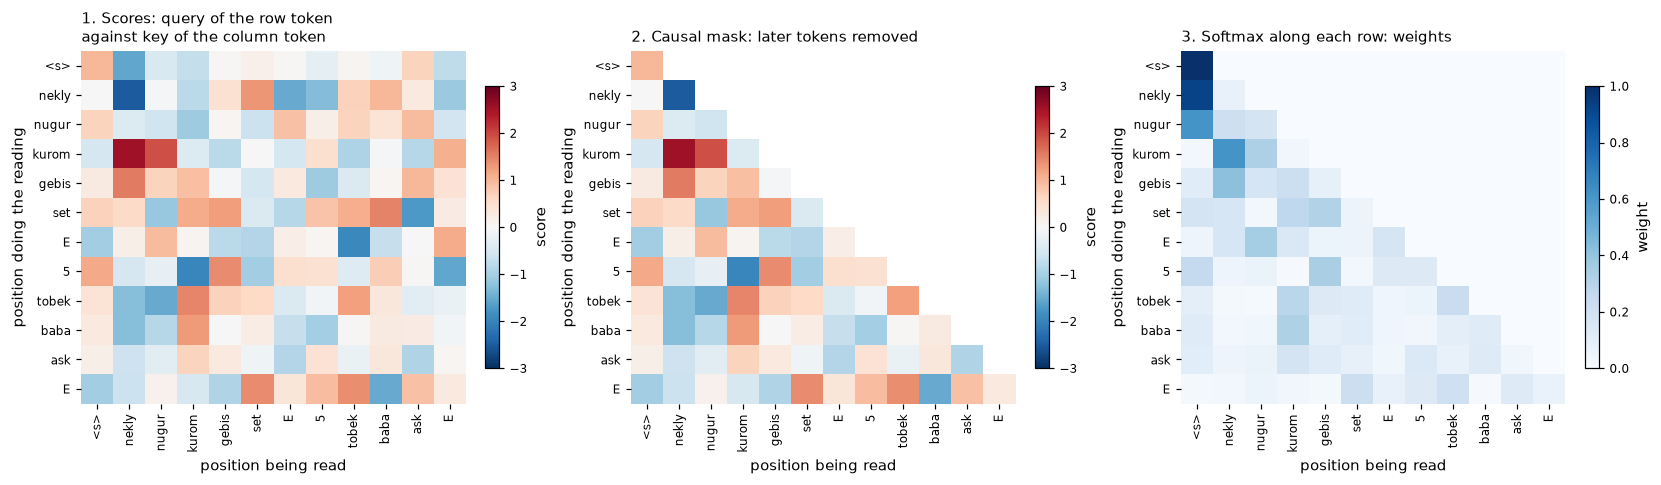

each row of the weights sums to [1.0, 1.0, 1.0, 1.0] ...
output shape: (12, 16) (one vector per position, all computed at once)


In [2]:
set_seed(0)
doc = test["tokens"][3][:12]; words = [W.WORDS[t] for t in doc]
d = 16
x = torch.randn(len(doc), d)                                  # stand-ins for the token vectors
Wq, Wk, Wv = (torch.randn(d, d) / d ** 0.5 for _ in range(3))
q, k, v = x @ Wq, x @ Wk, x @ Wv
scores = q @ k.T / d ** 0.5                                   # every position against every position: one matrix product
causal = torch.ones(len(doc), len(doc)).tril().bool()
weights = torch.softmax(scores.masked_fill(~causal, float("-inf")), -1)
out = weights @ v                                             # one new vector per position

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
viz.heat(axes[0], scores, xlabels=words, ylabels=words, cmap="RdBu_r", vmin=-3, vmax=3, cbar="score")
axes[0].set_title("1. Scores: query of the row token\nagainst key of the column token")
viz.heat(axes[1], np.where(causal, scores, np.nan), xlabels=words, ylabels=words, cmap="RdBu_r", vmin=-3, vmax=3, cbar="score")
axes[1].set_title("2. Causal mask: later tokens removed")
viz.heat(axes[2], weights, xlabels=words, ylabels=words, cmap="Blues", vmin=0, vmax=1, cbar="weight")
axes[2].set_title("3. Softmax along each row: weights")
for ax in axes:
    ax.set_xlabel("position being read"); ax.set_ylabel("position doing the reading")
plt.show()
print("each row of the weights sums to", weights.sum(-1).round(decimals=3).tolist()[:4], "...")
print("output shape:", tuple(out.shape), "(one vector per position, all computed at once)")

Two things are worth noticing. All positions are computed in one matrix product, with no loop over time. And nothing
in the calculation knows where a token is: shuffle the earlier tokens and the weighted sum is unchanged. Position has
to be supplied separately, which is the subject of section 4.

## 2. The 2017 block

A transformer layer wraps attention in four more ingredients ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)):

* **Several heads.** The attention is run several times in parallel with different, smaller $W_Q, W_K, W_V$, and the
  outputs are concatenated. One head can track the recent words while another looks for a binding.
* **A feed-forward network** applied to each position separately, $\text{FFN}(x) = W_2\,\text{ReLU}(W_1 x)$, four
  times wider than the model. Attention moves information between positions; this layer transforms it.
* **Residual connections** ([He et al., 2015](https://arxiv.org/abs/1512.03385)): each sub-layer adds its output to its input, so the token's own vector is
  carried through.
* **Layer normalisation** ([Ba et al., 2016](https://arxiv.org/abs/1607.06450)) after each addition: $x \leftarrow \text{LayerNorm}(x + \text{sublayer}(x))$.

Position is supplied by adding a fixed vector of sines and cosines to each token vector:
$$PE_{t,2i} = \sin\!\big(t / 10000^{2i/d}\big), \qquad PE_{t,2i+1} = \cos\!\big(t / 10000^{2i/d}\big).$$

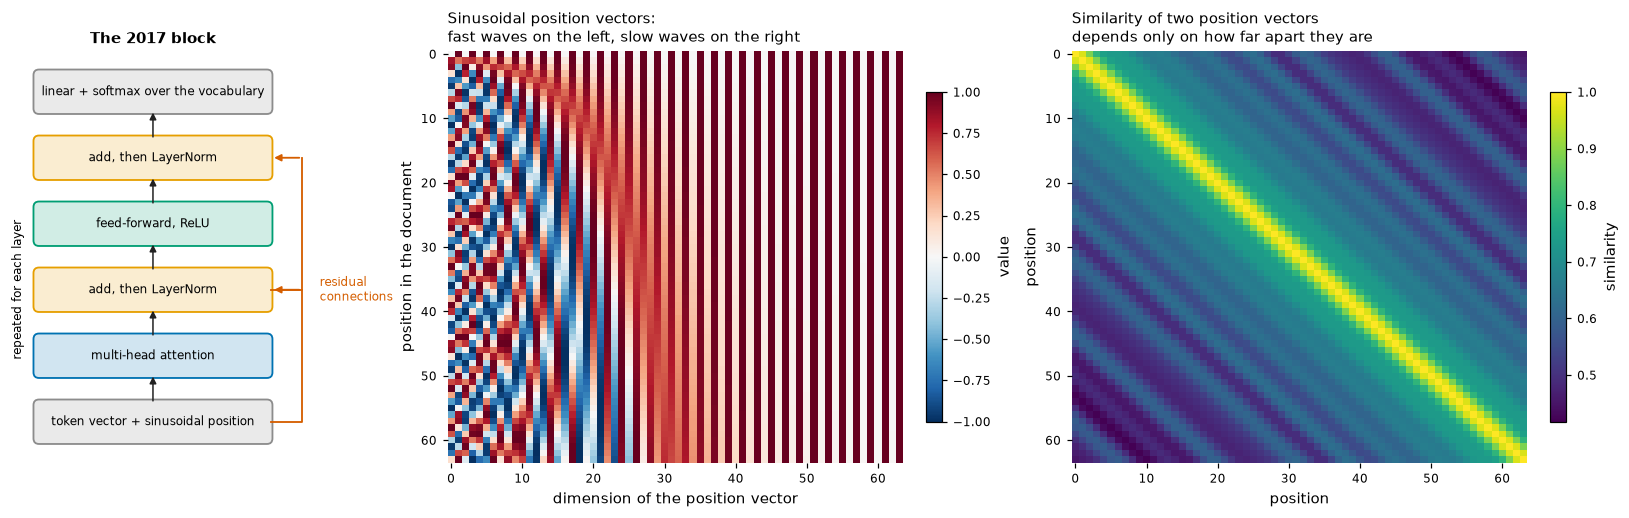

In [3]:
def block_diagram(ax, x, rows, title):
    # rows, bottom to top: (text, colour, skip) where skip = how many boxes below the residual branch starts (0 = none)
    boxes = [(x, i * 0.95, 3.4, 0.6, text, col) for i, (text, col, skip) in enumerate(rows)]
    arrows = [(x + 1.7, (i - 1) * 0.95 + 0.6, x + 1.7, i * 0.95) for i in range(1, len(rows))]
    viz.diagram(ax, boxes, arrows, fontsize=8)
    for i, (text, col, skip) in enumerate(rows):
        if skip:
            y0, y1 = (i - skip) * 0.95 + 0.3, i * 0.95 + 0.3
            ax.plot([x + 3.4, x + 3.85, x + 3.85], [y0, y0, y1], color=viz.VERMILION, lw=1.2)
            ax.annotate("", (x + 3.4, y1), (x + 3.85, y1), arrowprops=dict(arrowstyle="-|>", color=viz.VERMILION, lw=1.2))
    ax.text(x + 1.7, len(rows) * 0.95 + 0.05, title, ha="center", fontsize=10, fontweight="bold")
    ax.autoscale_view()

BLOCK_2017 = [("token vector + sinusoidal position", viz.GREY, 0), ("multi-head attention", viz.BLUE, 0), ("add, then LayerNorm", viz.ORANGE, 2),
              ("feed-forward, ReLU", viz.GREEN, 0), ("add, then LayerNorm", viz.ORANGE, 2), ("linear + softmax over the vocabulary", viz.GREY, 0)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1.0, 1.2, 1.2]))
block_diagram(axes[0], 0, BLOCK_2017, "The 2017 block")
axes[0].text(4.1, 2.2, "residual\nconnections", color=viz.VERMILION, fontsize=8, va="center")
axes[0].text(-0.25, 2.2, "repeated for each layer", rotation=90, fontsize=8, va="center", ha="center")
pe = T.sinusoidal(64, 64).numpy()
viz.heat(axes[1], pe, cmap="RdBu_r", vmin=-1, vmax=1, cbar="value")
axes[1].set_xlabel("dimension of the position vector"); axes[1].set_ylabel("position in the document")
axes[1].set_title("Sinusoidal position vectors:\nfast waves on the left, slow waves on the right")
viz.heat(axes[2], pe @ pe.T / 32, cmap="viridis", cbar="similarity")
axes[2].set_xlabel("position"); axes[2].set_ylabel("position")
axes[2].set_title("Similarity of two position vectors\ndepends only on how far apart they are")
plt.show()

The whole model is in `prelib/transformer.py` (about 200 lines, with every design choice of this notebook as a
keyword). We train the 2017 block as the paper did, with a learning-rate **warm-up** (the rate rises from zero over
the first 200 steps), and retrain the attention LSTM of notebook 02 in the same session so that the two are measured
side by side. Both have a 64-dimensional state; the transformer has two layers and four heads.

2017 block                         gap to floor 0.159   recall with 1 / 2 / 3 bindings alive: 0.13 / 0.14 / 0.14   (40s)
LSTM + dot-product attention       gap to floor 0.049   recall with 1 / 2 / 3 bindings alive: 1.00 / 1.00 / 1.00   (37s)


,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,parameters,seconds
LSTM + dot-product attention,0.049,0.036,1.000,0.999,0.999,57105,37
2017 block,0.159,0.044,0.132,0.142,0.138,109905,40


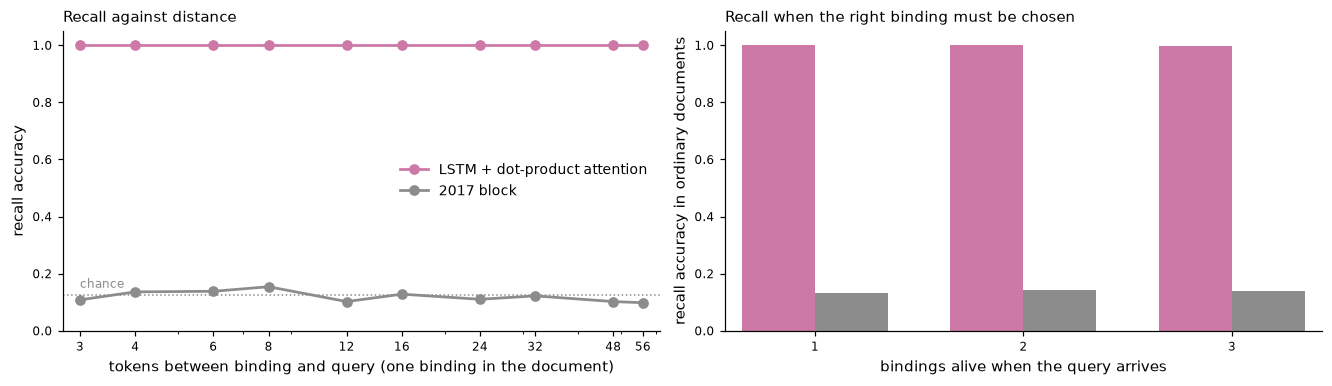

In [4]:
fit("2017 block", warmup=200)                      # the defaults of T.Transformer are the 2017 choices
set_seed(0)
lstm = R.RecurrentLM("lstm", d=64, attention="dot"); t0 = time.time()
C.train_lm(lstm, train["tokens"], steps=1500, batch=64, lr=2e-3)
score("LSTM + dot-product attention", lstm, time.time() - t0)

AB = ["LSTM + dot-product attention", "2017 block"]
display(table(AB).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for n, col in zip(AB, [viz.PINK, viz.GREY]):
    axes[0].plot(dists, [res[n]["recall"][d] for d in dists], "o-", color=col, label=n)
axes[0].axhline(1 / 8, color=viz.GREY, ls=":", lw=1); axes[0].text(dists[0], 0.15, "chance", fontsize=8, color=viz.GREY)
axes[0].set_xscale("log"); axes[0].set_xticks(dists); axes[0].set_xticklabels(dists); axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", which="minor", labelbottom=False)
axes[0].set_xlabel("tokens between binding and query (one binding in the document)"); axes[0].set_ylabel("recall accuracy")
axes[0].set_title("Recall against distance"); axes[0].legend()
x = np.arange(1, 4)
for k, (n, col) in enumerate(zip(AB, [viz.PINK, viz.GREY])):
    axes[1].bar(x + (k - 0.5) * 0.35, res[n]["bindings"].values, 0.35, color=col, label=n)
axes[1].set_xticks(x); axes[1].set_xlabel("bindings alive when the query arrives"); axes[1].set_ylabel("recall accuracy in ordinary documents")
axes[1].set_ylim(0, 1.05); axes[1].set_title("Recall when the right binding must be chosen")
plt.show()

**Reading the result.** The comparison does not favour the transformer. After 1,500 steps the 2017 block has a gap
to the floor of 0.16 nats per token, three times the LSTM's 0.05, and its recall is at chance (0.13) at every
distance, while the attention LSTM is at 1.00 with one, two or three bindings alive. On filler words the two are
close (0.044 against 0.036): the transformer has learned the local word statistics and has not learned the lookup.
It is not short of capacity, with about twice the LSTM's parameters (110,000 against 57,000).

One caution about the recall number. In this model recall switches on suddenly, late in the budget. In a development
run that differed only in the number of CPU threads, which changes floating-point rounding, the same configuration
was at chance until step 1,000 and reached 0.73 single-binding recall by step 1,500. So "at chance" here means "had
not switched on yet in this run". The training curves in section 3 are the steadier evidence that this block learns
slowly.

### What about speed?

The usual argument for the transformer is parallelism: an LSTM needs one step per token, each waiting for the last,
while a transformer layer handles all positions at once. The cell below times one training step of each model on
batches of 64 documents of increasing length.

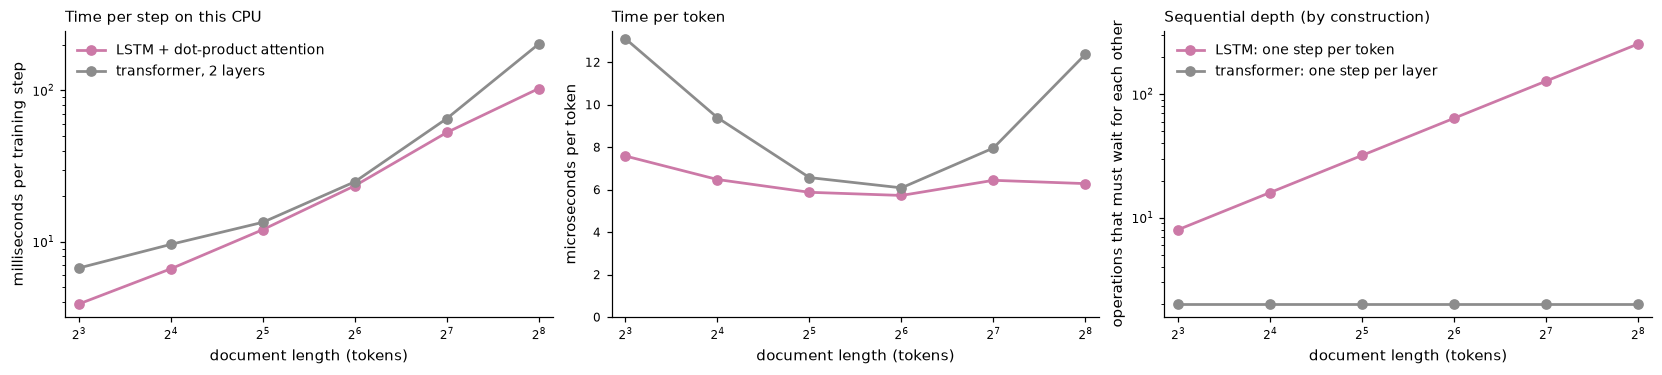

,LSTM + dot-product attention,"transformer, 2 layers"
document length,,
8,3.9,6.7
16,6.6,9.6
32,12.0,13.4
64,23.4,24.9
128,52.7,65.2
256,102.9,202.7


In [5]:
def step_ms(m, L, reps=5):
    x = torch.randint(5, W.VOCAB, (64, L)); ts = []
    for _ in range(reps):
        t0 = time.time(); loss = m(x).logsumexp(-1).mean(); m.zero_grad(); loss.backward(); ts.append(time.time() - t0)
    return 1000 * float(np.median(ts))
lengths = [8, 16, 32, 64, 128, 256]
set_seed(0)
timing = pd.DataFrame({"LSTM + dot-product attention": [step_ms(R.RecurrentLM("lstm", d=64, attention="dot"), L) for L in lengths],
                       "transformer, 2 layers": [step_ms(T.Transformer(), L) for L in lengths]}, index=lengths)
timing.index.name = "document length"
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
for n, col in zip(timing, [viz.PINK, viz.GREY]):
    axes[0].plot(lengths, timing[n], "o-", color=col, label=n)
    axes[1].plot(lengths, 1000 * timing[n] / (64 * np.array(lengths)), "o-", color=col, label=n)
axes[0].set_xscale("log", base=2); axes[0].set_yscale("log"); axes[0].set_xlabel("document length (tokens)"); axes[0].set_ylabel("milliseconds per training step")
axes[0].set_title("Time per step on this CPU"); axes[0].legend()
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("document length (tokens)"); axes[1].set_ylabel("microseconds per token"); axes[1].set_ylim(0)
axes[1].set_title("Time per token")
axes[2].plot(lengths, lengths, "o-", color=viz.PINK, label="LSTM: one step per token")
axes[2].plot(lengths, [2] * len(lengths), "o-", color=viz.GREY, label="transformer: one step per layer")
axes[2].set_xscale("log", base=2); axes[2].set_yscale("log"); axes[2].set_xlabel("document length (tokens)"); axes[2].set_ylabel("operations that must wait for each other")
axes[2].set_title("Sequential depth (by construction)"); axes[2].legend()
plt.show()
display(timing.round(1))

**Reading the result.** On this CPU the transformer has no speed advantage. At the training length of 64 tokens the
two models cost about the same per token; the LSTM is faster on short documents; and at 256 tokens the transformer
is close to twice as slow, because its attention matrix grows with the square of the length.

The transformer's advantage is the right-hand panel. An LSTM's steps must run one after another, 256 of them for a
256-token document. A transformer needs one step per layer, and each step is a batch of matrix products over all
positions. Hardware that runs many operations at once (a GPU) turns that into speed; four CPU threads working on
matrices this small do not. The argument made in 2017 was about training on such hardware at scale, and it is one
of the things a laptop experiment with a 64-dimensional model cannot reproduce.

# Part B · Five changes made since 2017

Each section below changes **one** thing, keeps the 1,500-step budget, and reports what moved. The models are tiny, so
several of these changes will turn out to make no measurable difference here. That is reported as it is, with the
reason the field adopted the change anyway.

## 3. Design choice 1: where the normalisation goes, and which one

The 2017 block normalises **after** the addition, so the normalisation sits on the residual path:
$$\textbf{post-norm:}\quad x \leftarrow \text{Norm}\big(x + f(x)\big) \qquad\qquad \textbf{pre-norm:}\quad x \leftarrow x + f\big(\text{Norm}(x)\big).$$
With pre-norm the residual path is a plain sum from the first layer to the last, and each sub-layer reads a
normalised copy. [Xiong et al., 2020](https://arxiv.org/abs/2002.04745) showed that this is what removes the need for a warm-up: post-norm models are
sensitive to the size of the first updates, and more so as they get deeper. GPT-2 and nearly every later language
model use pre-norm.

The second change is the normalisation itself. LayerNorm subtracts the mean, divides by the standard deviation, then
applies a learned gain and bias. **RMSNorm** ([Zhang & Sennrich, 2019](https://arxiv.org/abs/1910.07467)) keeps only the division:
$$\text{RMSNorm}(x) = g \odot \frac{x}{\sqrt{\tfrac{1}{d}\sum_i x_i^2}} .$$

Two experiments. First, a deliberately harder setting: six layers and a learning rate 2.5 times larger, trained for
300 steps with post-norm, post-norm plus warm-up, and pre-norm. Second, the standard two-layer model with each
change in turn.

In [6]:
def gradient_by_layer(norm, n_layer=8, seeds=3):
    # size of the first gradient for each block's weights, averaged over three initialisations
    x = torch.as_tensor(train["tokens"][:64]); out = []
    for s in range(seeds):
        set_seed(s); m = T.Transformer(n_layer=n_layer, norm=norm); m.train()
        F.cross_entropy(m(x)[:, 1:].reshape(-1, W.VOCAB), x[:, 1:].reshape(-1)).backward()
        out.append([float(torch.cat([p.grad.flatten() for p in b.parameters()]).norm()) for b in m.blocks])
    return np.mean(out, 0)
g_post, g_pre = gradient_by_layer("post"), gradient_by_layer("pre")

deep = {}
for name, kw, wu in [("post-norm, no warm-up", dict(norm="post"), 0), ("post-norm, 150 warm-up steps", dict(norm="post"), 150),
                     ("pre-norm, no warm-up", dict(norm="pre"), 0)]:
    set_seed(0)
    deep[name] = C.train_lm(T.Transformer(n_layer=6, **kw), train["tokens"], steps=300, lr=5e-3, warmup=wu)
    print(f"6 layers, learning rate 0.005, {name:30s} loss over the last 20 steps: {np.mean(deep[name][-20:]):.2f}")

fit("pre-norm", norm="pre")
fit("pre-norm + RMSNorm", norm="pre", norm_type="rms")

6 layers, learning rate 0.005, post-norm, no warm-up          loss over the last 20 steps: 4.19
6 layers, learning rate 0.005, post-norm, 150 warm-up steps   loss over the last 20 steps: 2.76
6 layers, learning rate 0.005, pre-norm, no warm-up           loss over the last 20 steps: 2.96
pre-norm                           gap to floor 0.101   recall with 1 / 2 / 3 bindings alive: 0.87 / 0.55 / 0.38   (42s)
pre-norm + RMSNorm                 gap to floor 0.085   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.39   (45s)


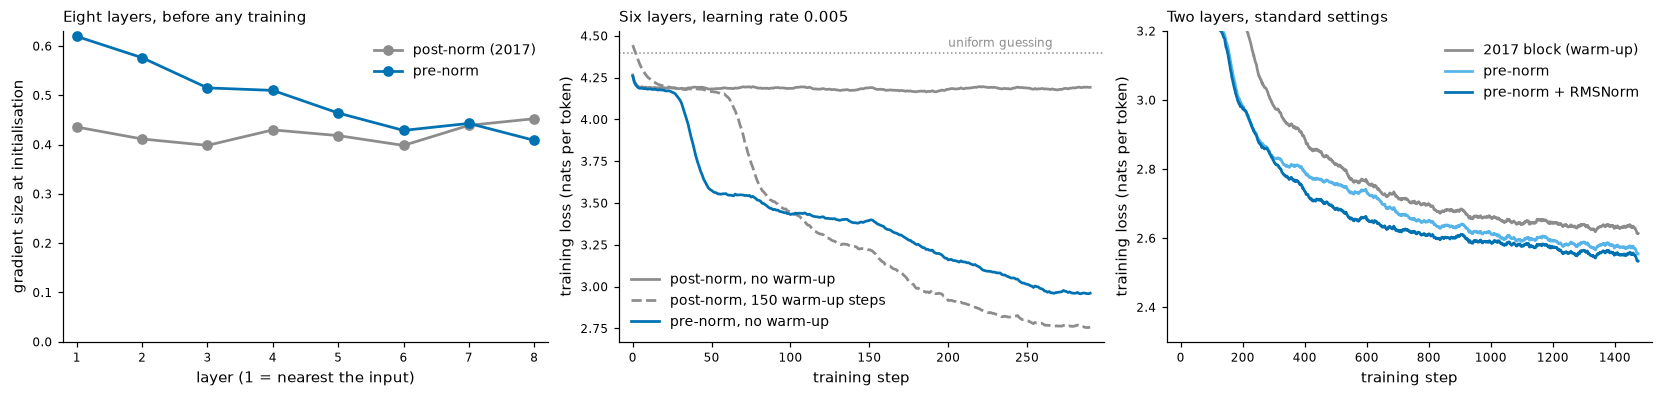

,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,parameters,seconds
2017 block,0.159,0.044,0.132,0.142,0.138,109905,40
pre-norm,0.101,0.037,0.872,0.552,0.380,110033,42
pre-norm + RMSNorm,0.085,0.026,1.000,0.560,0.392,109713,45


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(range(1, 9), g_post, "o-", color=viz.GREY, label="post-norm (2017)"); axes[0].plot(range(1, 9), g_pre, "o-", color=viz.BLUE, label="pre-norm")
axes[0].set_ylim(0); axes[0].set_xlabel("layer (1 = nearest the input)"); axes[0].set_ylabel("gradient size at initialisation")
axes[0].set_title("Eight layers, before any training"); axes[0].legend()
smooth = lambda v, k=10: np.convolve(v, np.ones(k) / k, mode="valid")
for (name, ls), col, style in zip(deep.items(), [viz.GREY, viz.GREY, viz.BLUE], ["-", "--", "-"]):
    axes[1].plot(smooth(ls), color=col, ls=style, label=name)
axes[1].axhline(np.log(W.VOCAB), color=viz.GREY, ls=":", lw=1); axes[1].text(200, np.log(W.VOCAB) + 0.04, "uniform guessing", fontsize=8, color=viz.GREY)
axes[1].set_xlabel("training step"); axes[1].set_ylabel("training loss (nats per token)")
axes[1].set_title("Six layers, learning rate 0.005"); axes[1].legend()
NORM = ["2017 block", "pre-norm", "pre-norm + RMSNorm"]
for n, col in zip(NORM, [viz.GREY, viz.SKY, viz.BLUE]):
    axes[2].plot(smooth(res[n]["losses"], 25), color=col, label=n + (" (warm-up)" if n == "2017 block" else ""))
axes[2].set_ylim(2.3, 3.2); axes[2].set_xlabel("training step"); axes[2].set_ylabel("training loss (nats per token)")
axes[2].set_title("Two layers, standard settings"); axes[2].legend()
plt.show()
display(table(NORM).round(3))

**Reading the result.**

* *At initialisation* (left) the gradients are of similar size in both arrangements at every depth. With eight
  layers, the difference between post- and pre-norm is not visible before training starts.
* *With six layers and a large learning rate* (middle) it is. Post-norm without warm-up never leaves a loss of 4.19,
  close to uniform guessing (4.39): the first large updates put it somewhere it does not recover from in 300 steps.
  The same model with 150 warm-up steps trains normally (2.76), and pre-norm trains with no warm-up at all (2.96).
  Warm-up is a remedy for post-norm; pre-norm removes the need for the remedy. Note that post-norm *with* warm-up
  ends slightly ahead here. What pre-norm buys is robustness, not a better final loss.
* *With two layers at the standard settings* (right, and the table) pre-norm reaches a gap of 0.101 against 0.159
  for the 2017 block and has learned single-binding recall (0.87). Replacing LayerNorm by RMSNorm gives 0.085 and
  recall of 1.00. RMSNorm is normally described as a cheaper equivalent of LayerNorm, so we read this last step as
  recall happening to switch on earlier in one run, not as evidence that RMSNorm is better. One seed cannot tell
  those apart.

## 4. Design choice 2: how position is represented

Section 1 showed that attention by itself ignores order. There have been four generations of answers.

| Scheme | Where position enters | Formula |
|---|---|---|
| **Sinusoidal** ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) | added to the token vector, once, at the input | $x_t + PE_t$, fixed waves |
| **Learned absolute** (BERT, GPT-2) | same place | $x_t + P_t$, one trained vector per position |
| **Relative bias** ([Shaw et al., 2018](https://arxiv.org/abs/1803.02155); the simplified form used by T5) | inside every attention score | $\text{score}_{tj} + b_{t-j}$, one trained number per head and distance |
| **ALiBi** ([Press et al., 2021](https://arxiv.org/abs/2108.12409)) | inside every attention score | $\text{score}_{tj} - m_h\,(t-j)$, a fixed slope per head, nothing trained |
| **RoPE** ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) | inside every attention score | rotate $q_t$ and $k_j$ by angles proportional to $t$ and $j$ before the dot product |

The first two tell the model **where each token is**. The last three tell attention **how far apart two tokens are**,
which is usually what matters: "the word just before", "the value two tokens after `set`".

### How RoPE works

RoPE splits each query and key into pairs of coordinates and treats each pair as a point in the plane. The pair at
position $t$ is rotated by the angle $t\theta_i$, with a different speed $\theta_i = 10000^{-2i/d}$ for each pair:
$$\begin{pmatrix} q'_{2i} \\ q'_{2i+1} \end{pmatrix} =
\begin{pmatrix} \cos t\theta_i & -\sin t\theta_i \\ \sin t\theta_i & \cos t\theta_i \end{pmatrix}
\begin{pmatrix} q_{2i} \\ q_{2i+1} \end{pmatrix}.$$
A dot product between two vectors depends only on their lengths and the angle between them. Rotating the query by
$t\theta$ and the key by $j\theta$ changes the angle between them by $(t-j)\theta$, so the score depends on the
**offset** $t-j$ and not on where the pair sits in the document. The animation shows one coordinate pair: first the
query and key move through the document together (both rotate, the score stays put), then the query moves away from
the key (the score changes).

In [8]:
theta = 0.3
q0, k0 = np.array([1.0, 0.25]), np.array([0.75, 0.7])
rot = lambda v, a: np.array([v[0] * np.cos(a) - v[1] * np.sin(a), v[0] * np.sin(a) + v[1] * np.cos(a)])
where = [(f, f + 2) for f in range(16)] + [(15, 17 + f) for f in range(1, 17)]            # (key position, query position) per frame
rope_scores = [rot(q0, m * theta) @ rot(k0, n * theta) for n, m in where]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
def frame(f):
    n, m = where[f]
    ax = axes[0]; ax.clear()
    ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color=viz.GREY, lw=0.8, ls=":"))
    for v, col, lab in [(rot(k0, n * theta), viz.ORANGE, f"key at position {n}"), (rot(q0, m * theta), viz.BLUE, f"query at position {m}")]:
        ax.annotate("", v, (0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2))
        ax.plot([], [], color=col, lw=2.2, label=lab)
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title("moving together: offset stays at 2" if f < 16 else f"query moves away: offset {m - n}")
    ax = axes[1]; ax.clear()
    ax.plot(range(f + 1), rope_scores[:f + 1], "o-", color=viz.BLACK, ms=3)
    ax.axvline(15.5, color=viz.GREY, ls=":", lw=1)
    ax.set_xlim(-1, len(where)); ax.set_ylim(-1.3, 1.3); ax.set_xlabel("animation frame"); ax.set_ylabel("score = query . key")
    ax.set_title("the score depends only on the offset")
viz.save_gif(fig, frame, range(len(where)), "nb03_rope_rotation.gif", fps=4)

saved figures/nb03_rope_rotation.gif  (32 frames drawn, 131 kB)


'figures/nb03_rope_rotation.gif'

![One RoPE coordinate pair: when query and key move through the document together both rotate and the score is unchanged; when the offset grows the score changes](figures/nb03_rope_rotation.gif)

### Try it: positions and frequencies

Each coordinate pair turns at its own speed. Fast pairs separate neighbouring positions; slow pairs barely move over a
whole document, which leaves room for matching on content regardless of distance. Move the two positions and pick a
pair. The right-hand panel shows the score two identical vectors would get, pair by pair and in total, as a function
of the offset.

Static preview at the default settings {'query_position': 20, 'key_position': 12, 'pair': 2}. Run the notebook to get the controls.


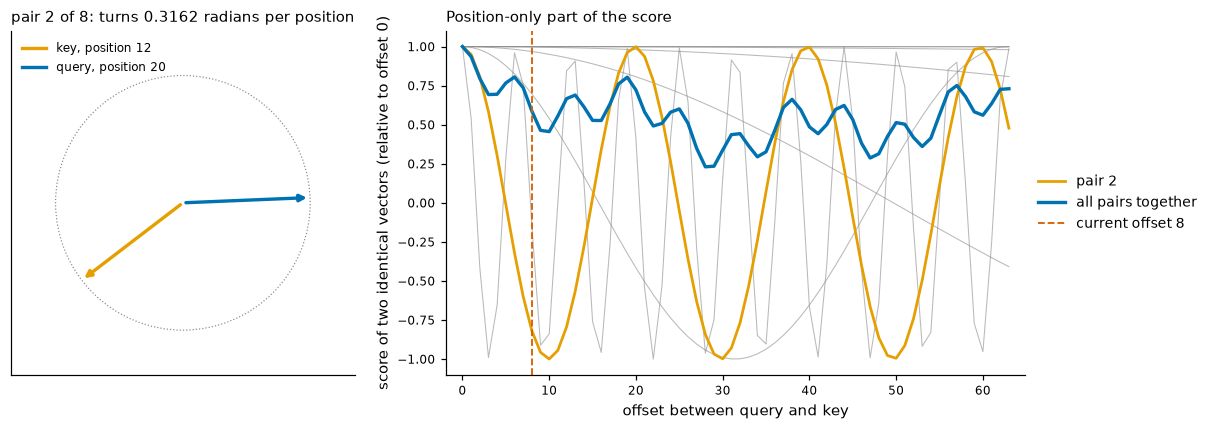

In [9]:
HEAD_DIM = 16                                               # 64 dimensions / 4 heads, as in the models below
rope_freq = 10000.0 ** (-np.arange(0, HEAD_DIM, 2) / HEAD_DIM)
def rope_explorer(query_position=20, key_position=12, pair=1):
    th = rope_freq[pair - 1]; off = np.arange(0, 64)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1, 1.6]))
    ax = axes[0]
    ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color=viz.GREY, lw=0.8, ls=":"))
    for pos, col, lab in [(key_position, viz.ORANGE, f"key, position {key_position}"), (query_position, viz.BLUE, f"query, position {query_position}")]:
        ax.annotate("", rot(np.array([1.0, 0.0]), pos * th), (0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2))
        ax.plot([], [], color=col, lw=2.2, label=lab)
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"pair {pair} of {len(rope_freq)}: turns {th:.4f} radians per position")
    ax = axes[1]
    for i, f in enumerate(rope_freq):
        ax.plot(off, np.cos(off * f), color=viz.GREY, lw=0.7, alpha=0.6)
    ax.plot(off, np.cos(off * th), color=viz.ORANGE, lw=1.8, label=f"pair {pair}")
    ax.plot(off, np.cos(off[:, None] * rope_freq[None]).mean(1), color=viz.BLUE, lw=2.2, label="all pairs together")
    ax.axvline(abs(query_position - key_position), color=viz.VERMILION, ls="--", lw=1.2, label=f"current offset {abs(query_position - key_position)}")
    ax.set_xlabel("offset between query and key"); ax.set_ylabel("score of two identical vectors (relative to offset 0)")
    ax.set_title("Position-only part of the score"); ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    plt.show()
viz.explore(rope_explorer, query_position=(0, 63, 1, 20), key_position=(0, 63, 1, 12), pair=(1, 8, 1, 2))

### The ablation

Six models, identical except for the position scheme (all pre-norm with RMSNorm, ReLU feed-forward). Besides the usual
measurements, each is tested on something it never saw in training: **documents twice as long** (128 tokens; we
measure the gap to the floor on positions 64 to 127) and a **recall query 100 tokens after its binding**.

In [10]:
base = dict(norm="pre", norm_type="rms")
for name, pos in [("learned absolute", "learned"), ("relative bias", "relative"), ("ALiBi", "alibi"), ("RoPE", "rope"), ("no positions", "none")]:
    fit(name, pos=pos, **base)
POS = ["pre-norm + RMSNorm", "learned absolute", "relative bias", "ALiBi", "RoPE", "no positions"]
POS_LABEL = {"pre-norm + RMSNorm": "sinusoidal (2017)"}
pos_table = table(POS, extra=(LONG, FAR), labels=POS_LABEL)
display(pos_table.round(3))

learned absolute                   gap to floor 0.060   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.41   (44s)
relative bias                      gap to floor 0.063   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.40   (44s)
ALiBi                              gap to floor 0.066   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.57 / 0.40   (44s)
RoPE                               gap to floor 0.058   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.41   (48s)
no positions                       gap to floor 0.089   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.57 / 0.41   (44s)


,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,"gap, positions 64-127",recall at distance 100,parameters,seconds
sinusoidal (2017),0.085,0.026,1.0,0.560,0.392,0.850,0.780,109713,45
learned absolute,0.060,0.032,1.0,0.556,0.406,0.318,0.863,113809,44
relative bias,0.063,0.034,1.0,0.561,0.400,0.117,1.000,109977,44
ALiBi,0.066,0.037,1.0,0.570,0.398,0.113,1.000,109713,44
RoPE,0.058,0.026,1.0,0.556,0.410,0.130,0.973,109713,48
no positions,0.089,0.063,1.0,0.569,0.405,0.182,1.000,109713,44


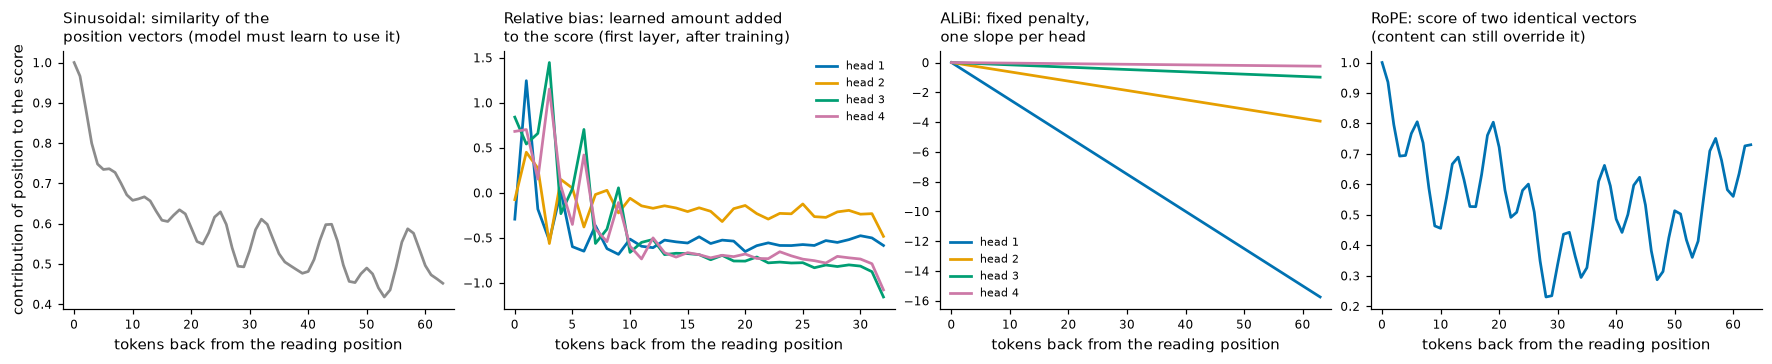

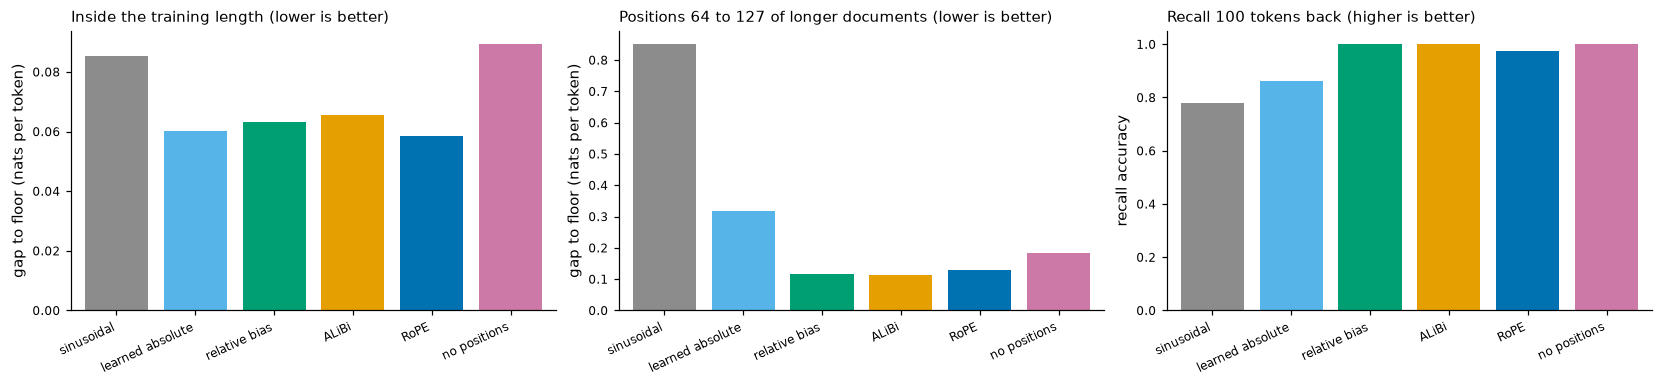

In [11]:
off = np.arange(0, 64); pe = T.sinusoidal(128, 64).numpy()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
axes[0].plot(off, [pe[64] @ pe[64 - o] / 32 for o in off], color=viz.GREY)
axes[0].set_title("Sinusoidal: similarity of the\nposition vectors (model must learn to use it)")
rel = models["relative bias"].blocks[0].attn.rel.detach().numpy()
for h in range(4):
    axes[1].plot(np.arange(rel.shape[1]), rel[h], color=viz.CYCLE[h], label=f"head {h + 1}")
axes[1].set_title("Relative bias: learned amount added\nto the score (first layer, after training)"); axes[1].legend(fontsize=7)
slopes = models["ALiBi"].blocks[0].attn.slopes.numpy()
for h in range(4):
    axes[2].plot(off, -slopes[h] * off, color=viz.CYCLE[h], label=f"head {h + 1}")
axes[2].set_title("ALiBi: fixed penalty,\none slope per head"); axes[2].legend(fontsize=7)
axes[3].plot(off, np.cos(off[:, None] * rope_freq[None]).mean(1), color=viz.BLUE)
axes[3].set_title("RoPE: score of two identical vectors\n(content can still override it)")
for ax in axes:
    ax.set_xlabel("tokens back from the reading position")
axes[0].set_ylabel("contribution of position to the score")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
cols = [viz.GREY, viz.SKY, viz.GREEN, viz.ORANGE, viz.BLUE, viz.PINK]
for ax, col, title in zip(axes, ["gap to floor", LONG, FAR], ["Inside the training length (lower is better)",
                          "Positions 64 to 127 of longer documents (lower is better)", "Recall 100 tokens back (higher is better)"]):
    ax.bar(range(len(pos_table)), pos_table[col], color=cols)
    ax.set_xticks(range(len(pos_table))); ax.set_xticklabels([s.replace(" (2017)", "") for s in pos_table.index], rotation=25, ha="right")
    ax.set_title(title); ax.set_ylabel("gap to floor (nats per token)" if "gap" in col else "recall accuracy")
plt.show()

**Reading the result.**

* *Inside the training length* every scheme learns single-binding recall. The gaps run from 0.058 (RoPE) to 0.089
  (no positions); the four schemes that came after 2017 are within 0.008 of each other, and sinusoidal (0.085) is
  behind them.
* *No positions at all* works better than one might expect. Recall is perfect, because finding a value is a matter of
  content. What suffers is the filler words (gap 0.063, against 0.026 to 0.037 for the others), whose prediction
  depends on word order. That it is not far worse is a known effect: the causal mask leaks position, since a token
  that can see ten earlier tokens must be the eleventh ([Haviv et al., 2022](https://arxiv.org/abs/2203.16634)).
* *Beyond the training length* the sinusoidal model fails: its gap on positions 64 to 127 is 0.85, ten times its gap
  inside the training length. It was told *where* each token is, and it has never seen these addresses. Relative
  bias, ALiBi and RoPE stay between 0.11 and 0.13. The learned-absolute model (0.32) sits in between, but section 5
  will show that a difference of that size also appears between models with the same position scheme, so only the
  sinusoidal failure is established by this measurement.
* *Recall 100 tokens back* tells the same story from another side: 0.78 and 0.86 for the two absolute schemes, 0.97
  to 1.00 for the others.
* Between relative bias, ALiBi and RoPE this experiment cannot choose. ALiBi was designed for exactly this length
  test; RoPE became the default of the Llama family and most open models.

The learned relative biases (second panel of the first figure) show what the model wants from position: large values
for the last half-dozen tokens, which is what predicting word order needs, and a flat, slightly negative value for
everything further back.

## 5. Design choice 3: the feed-forward activation

The feed-forward layer of 2017 is $W_2\,\text{ReLU}(W_1 x)$. Two replacements followed.

* **GELU** ([Hendrycks & Gimpel, 2016](https://arxiv.org/abs/1606.08415)), used by BERT and GPT-2: a smooth curve that lets small negative inputs through
  slightly instead of cutting them to zero.
* **SwiGLU** ([Shazeer, 2020](https://arxiv.org/abs/2002.05202)), used by the Llama family ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)): a *gated* unit. One linear map proposes
  values, a second decides how much of each to let through,
  $$\text{SwiGLU}(x) = W_2\big(\text{SiLU}(W_1 x) \odot W_3 x\big), \qquad \text{SiLU}(z) = z\,\sigma(z).$$
  It has three matrices instead of two, so the hidden width is cut to two thirds to keep the parameter count equal.

RoPE + GELU                        gap to floor 0.058   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.41   (49s)
RoPE + SwiGLU                      gap to floor 0.059   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.41   (50s)


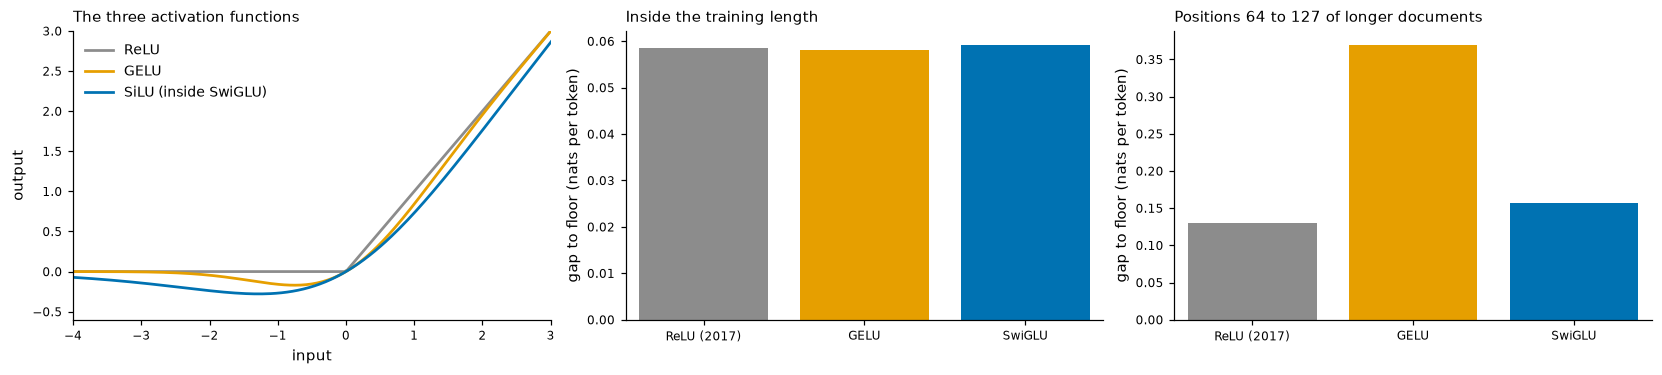

,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,"gap, positions 64-127",recall at distance 100,parameters,seconds
ReLU (2017),0.058,0.026,1.0,0.556,0.410,0.130,0.973,109713,48
GELU,0.058,0.035,1.0,0.562,0.412,0.370,1.000,109713,49
SwiGLU,0.059,0.032,1.0,0.564,0.411,0.157,1.000,108817,50


In [12]:
rope = dict(pos="rope", norm="pre", norm_type="rms")
fit("RoPE + GELU", ffn="gelu", **rope)
fit("RoPE + SwiGLU", ffn="swiglu", **rope)
FFN = ["RoPE", "RoPE + GELU", "RoPE + SwiGLU"]
FFN_LABEL = {"RoPE": "ReLU (2017)", "RoPE + GELU": "GELU", "RoPE + SwiGLU": "SwiGLU"}
ffn_table = table(FFN, extra=(LONG, FAR), labels=FFN_LABEL)
z = torch.linspace(-4, 4, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
for f, lab, col in [(F.relu, "ReLU", viz.GREY), (F.gelu, "GELU", viz.ORANGE), (F.silu, "SiLU (inside SwiGLU)", viz.BLUE)]:
    axes[0].plot(z, f(z), color=col, label=lab)
axes[0].set_xlim(-4, 3); axes[0].set_ylim(-0.6, 3); axes[0].set_xlabel("input"); axes[0].set_ylabel("output"); axes[0].set_title("The three activation functions"); axes[0].legend()
for ax, col, title in [(axes[1], "gap to floor", "Inside the training length"), (axes[2], LONG, "Positions 64 to 127 of longer documents")]:
    ax.bar(range(3), ffn_table[col], color=[viz.GREY, viz.ORANGE, viz.BLUE]); ax.set_xticks(range(3)); ax.set_xticklabels(ffn_table.index)
    ax.set_ylabel("gap to floor (nats per token)"); ax.set_title(title)
plt.show()
display(ffn_table.round(3))

**Reading the result.** Inside the training length the three activations are indistinguishable: gaps of 0.058, 0.058
and 0.059. At this scale the choice does not matter. The gains reported for GELU and SwiGLU are small and were
measured on models many orders of magnitude larger; nothing here confirms or contradicts them.

The right-hand panel is a caution about section 4. These three models use the same position scheme, yet their gap on
longer documents ranges from 0.13 to 0.37. That spread is run-to-run variation in how a model behaves outside its
training range, and it is the yardstick for the position ablation: the sinusoidal model's 0.85 is well outside it,
the learned-absolute model's 0.32 is not.

## 6. Design choice 4: grouped-query attention

This change is about the cost of **generating**, not about quality. When a model generates text one token at a time,
it keeps the keys and values of every earlier token for every layer and head, so that they are not recomputed. This
**key/value cache** grows with the length of the context and, in a large model serving many requests, it is what fills
the memory: $2 \times \text{layers} \times \text{heads} \times d_\text{head}$ numbers per token.

**Grouped-query attention** ([Ainslie et al., 2023](https://arxiv.org/abs/2305.13245)) lets several query heads share one key/value head. Each head still asks
its own question, but they read from fewer sets of keys and values. With one shared set it is called multi-query
attention; with one set per query head it is ordinary multi-head attention.

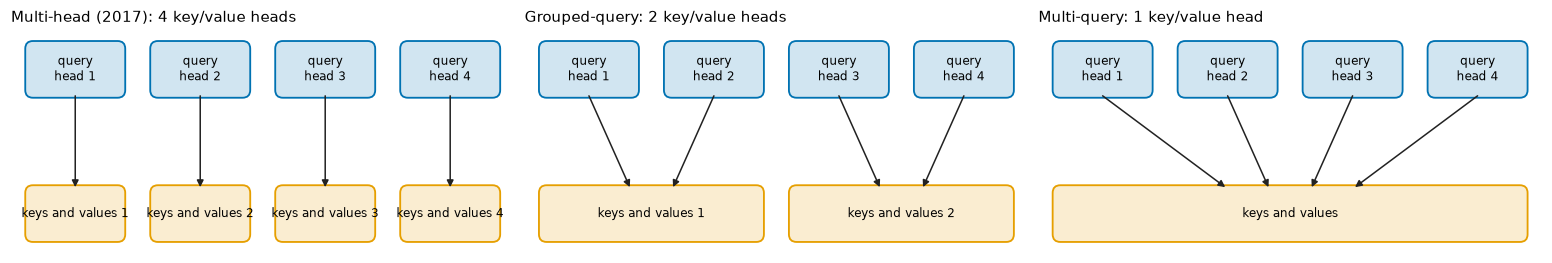

GQA, 2 key/value heads             gap to floor 0.063   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.56 / 0.40   (50s)
GQA, 1 key/value head              gap to floor 0.062   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.55 / 0.40   (48s)


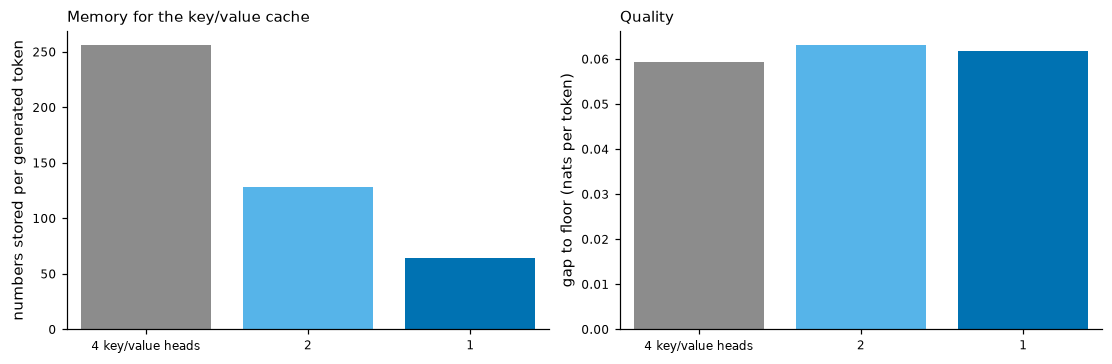

,cached numbers per token,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,parameters,seconds
"multi-head, 4 key/value heads",256,0.059,0.032,1.0,0.564,0.411,108817,50
"GQA, 2 key/value heads",128,0.063,0.041,1.0,0.558,0.404,100625,50
"GQA, 1 key/value head",64,0.062,0.036,1.0,0.553,0.404,96529,48


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 2.6))
for ax, n_kv, title in zip(axes, [4, 2, 1], ["Multi-head (2017): 4 key/value heads", "Grouped-query: 2 key/value heads", "Multi-query: 1 key/value head"]):
    group = 4 // n_kv; width = group * 1.3 - 0.3
    boxes = [(i * 1.3, 1.5, 1.0, 0.55, f"query\nhead {i + 1}", viz.BLUE) for i in range(4)]
    boxes += [(j * group * 1.3, 0, width, 0.55, "keys and values" + (f" {j + 1}" if n_kv > 1 else ""), viz.ORANGE) for j in range(n_kv)]
    arrows = [(i * 1.3 + 0.5, 1.5, (i // group) * group * 1.3 + width / 2 + (i % group - (group - 1) / 2) * 0.45, 0.55) for i in range(4)]
    viz.diagram(ax, boxes, arrows, fontsize=8); ax.set_title(title)
plt.show()

swiglu = dict(pos="rope", norm="pre", norm_type="rms", ffn="swiglu")
fit("GQA, 2 key/value heads", n_kv_head=2, **swiglu)
fit("GQA, 1 key/value head", n_kv_head=1, **swiglu)
GQA = ["RoPE + SwiGLU", "GQA, 2 key/value heads", "GQA, 1 key/value head"]
gqa_table = table(GQA, labels={"RoPE + SwiGLU": "multi-head, 4 key/value heads"})
gqa_table.insert(0, "cached numbers per token", [models[n].kv_cache_floats_per_token() for n in GQA])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(range(3), gqa_table["cached numbers per token"], color=[viz.GREY, viz.SKY, viz.BLUE]); axes[0].set_ylabel("numbers stored per generated token")
axes[0].set_title("Memory for the key/value cache")
axes[1].bar(range(3), gqa_table["gap to floor"], color=[viz.GREY, viz.SKY, viz.BLUE]); axes[1].set_ylabel("gap to floor (nats per token)")
axes[1].set_title("Quality")
for ax in axes:
    ax.set_xticks(range(3)); ax.set_xticklabels(["4 key/value heads", "2", "1"])
plt.show()
display(gqa_table.round(3))

**Reading the result.** Sharing keys and values cuts the cache from 256 numbers per token to 128 and to 64, and
removes 8,000 to 12,000 parameters. The gap moves from 0.059 to 0.063 and 0.062, within the variation seen between
equivalent models in section 5. At this scale the saving is free.

In a model with dozens of layers and a context of many thousands of tokens the cache runs to gigabytes per request,
which is why Llama 2 and 3 and the Mistral models use grouped-query attention. [Ainslie et al., 2023](https://arxiv.org/abs/2305.13245) report that a moderate
number of groups keeps quality close to full multi-head attention, while a single shared head loses some.

## 7. Design choice 5: mixture of experts

The feed-forward layers hold most of a transformer's parameters. A **mixture of experts** (MoE) replaces the single
feed-forward network with several, the *experts*, and a small **router** that sends each token to only a few of them
([Jacobs et al., 1991](https://doi.org/10.1162/neco.1991.3.1.79) for the idea; [Shazeer et al., 2017](https://arxiv.org/abs/1701.06538) for the sparse form used in language models):
$$r = W_r x, \qquad \mathcal{T} = \text{top-}k(r), \qquad g_e = \frac{\exp r_e}{\sum_{e' \in \mathcal{T}} \exp r_{e'}}\ (e \in \mathcal{T}), \qquad
\text{MoE}(x) = \sum_{e \in \mathcal{T}} g_e\, \text{FFN}_e(x).$$
The point is to separate two numbers that are the same in a dense model: the parameters the model **has**, and the
parameters each token **uses**. With 4 experts and top-1 routing ([Fedus et al., 2021](https://arxiv.org/abs/2101.03961)) the layer has four times the
feed-forward parameters, yet each token passes through one expert, the same computation as before. Mixtral
([Jiang et al., 2024](https://arxiv.org/abs/2401.04088)) uses 8 experts and routes each token to 2.

Routing has a known failure: the router can send almost everything to a few experts, leaving the others untrained.
The standard remedy is a **load-balancing loss** that penalises unequal use. We train the layer with and without it
and record, every 50 steps, which kinds of token go to which expert.

In [14]:
route_tok = test["tokens"][:200]
TYPES = [f"words ending -{s}" for s in W.SUFFIX] + ["'set' and 'ask'", "keys A-H", "values 1-8"]
ttype = W.WORD_CLASS[route_tok].copy()
ttype[(route_tok == W.SET) | (route_tok == W.ASK)] = 6
ttype[(route_tok >= W.KEY0) & (route_tok < W.KEY0 + 8)] = 7
ttype[(route_tok >= W.VAL0) & (route_tok < W.VAL0 + 8)] = 8

def routing(model):
    # share of each token type sent to each expert: array (layer, token type, expert)
    with torch.no_grad():
        model.hidden(torch.as_tensor(route_tok))
    out = []
    for blk in model.blocks:
        choice = blk.ffn.last_gate.argmax(-1).numpy()
        out.append([[np.mean(choice[ttype == k] == e) for e in range(blk.ffn.E)] for k in range(len(TYPES))])
    return np.array(out)

def load(model):
    with torch.no_grad():
        model.hidden(torch.as_tensor(route_tok))
    return np.array([blk.ffn.last_load.numpy() for blk in model.blocks])            # (layer, expert): share of tokens

route_hist = {}
def recorder(name):
    route_hist[name] = []
    def cb(step, model):
        if step % 50 == 0 or step == 1499:
            route_hist[name].append((step, routing(model), load(model)))
    return cb
fit("MoE, balanced", moe=dict(n_experts=4, top_k=1, balance=0.01), callback=recorder("MoE, balanced"), **swiglu)
fit("MoE, no balancing loss", moe=dict(n_experts=4, top_k=1, balance=0.0), callback=recorder("MoE, no balancing loss"), **swiglu)

def active_params(m):
    c = m.cfg["moe"]
    if not c:
        return m.n_params()
    expert = sum(p.numel() for b in m.blocks for p in b.ffn.experts.parameters())
    return int(m.n_params() - expert * (c["n_experts"] - c["top_k"]) / c["n_experts"])
MOE = ["RoPE + SwiGLU", "MoE, balanced", "MoE, no balancing loss"]
moe_table = table(MOE, labels={"RoPE + SwiGLU": "dense feed-forward"})
moe_table.insert(0, "parameters used per token", [active_params(models[n]) for n in MOE])
display(moe_table.round(3))

MoE, balanced                      gap to floor 0.065   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.55 / 0.40   (99s)
MoE, no balancing loss             gap to floor 0.065   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.57 / 0.40   (99s)


,parameters used per token,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,parameters,seconds
dense feed-forward,108817,0.059,0.032,1.0,0.564,0.411,108817,50
"MoE, balanced",109329,0.065,0.036,1.0,0.551,0.402,305169,99
"MoE, no balancing loss",109329,0.065,0.039,1.0,0.570,0.398,305169,99


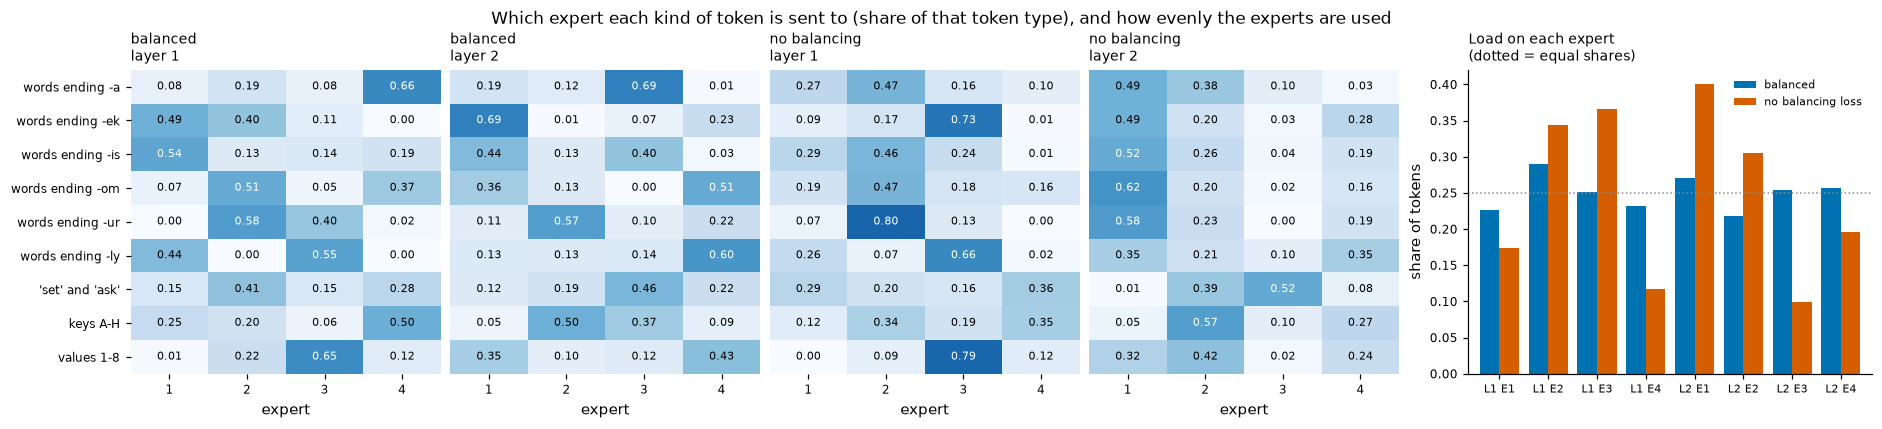

saved figures/nb03_moe_routing.gif  (31 frames drawn, 418 kB)


'figures/nb03_moe_routing.gif'

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.3]))
for j, name in enumerate(["MoE, balanced", "MoE, no balancing loss"]):
    Rt = routing(models[name])
    for l in range(2):
        ax = axes[2 * j + l]
        viz.heat(ax, Rt[l], xlabels=[f"{e + 1}" for e in range(4)], ylabels=TYPES if (j, l) == (0, 0) else None, annotate=True, cmap="Blues", vmin=0, vmax=1)
        if (j, l) != (0, 0):
            ax.set_yticks([])
        ax.set_xlabel("expert"); ax.set_title(f"{'balanced' if j == 0 else 'no balancing'}\nlayer {l + 1}", fontsize=9)
ax = axes[4]
for j, (name, col) in enumerate([("MoE, balanced", viz.BLUE), ("MoE, no balancing loss", viz.VERMILION)]):
    L = load(models[name]).reshape(-1)
    ax.bar(np.arange(8) + (j - 0.5) * 0.4, L, 0.4, color=col, label="balanced" if j == 0 else "no balancing loss")
ax.axhline(0.25, color=viz.GREY, ls=":", lw=1)
ax.set_xticks(range(8)); ax.set_xticklabels([f"L{l + 1} E{e + 1}" for l in range(2) for e in range(4)], fontsize=7)
ax.set_ylabel("share of tokens"); ax.set_title("Load on each expert\n(dotted = equal shares)", fontsize=9); ax.legend(fontsize=7)
fig.suptitle("Which expert each kind of token is sent to (share of that token type), and how evenly the experts are used", y=1.04)
plt.show()

hist = route_hist["MoE, balanced"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw=dict(width_ratios=[1.5, 1]))
def frame(f):
    step, Rt, L = hist[f]
    axes[0].clear(); axes[1].clear()
    viz.heat(axes[0], Rt[0], xlabels=[f"expert {e + 1}" for e in range(4)], ylabels=TYPES, cmap="Blues", vmin=0, vmax=1)
    axes[0].set_title(f"Layer 1 routing after {step + 1 if step else 0} training steps")
    axes[1].bar(range(4), L[0], color=viz.BLUE); axes[1].axhline(0.25, color=viz.GREY, ls=":", lw=1)
    axes[1].set_ylim(0, 1); axes[1].set_xticks(range(4)); axes[1].set_xticklabels([f"expert {e + 1}" for e in range(4)])
    axes[1].set_ylabel("share of tokens"); axes[1].set_title("Load")
viz.save_gif(fig, frame, range(len(hist)), "nb03_moe_routing.gif", fps=4)

![Routing in the first mixture-of-experts layer during training: token types are spread at random at first, then each type settles on an expert while the load stays near equal](figures/nb03_moe_routing.gif)

**Reading the result.**

* *Routing specialises without being told to.* After training, each kind of token goes mostly to one or two experts:
  in the first layer of the balanced model, 66% of the words ending in -a go to expert 4 and 65% of the values to
  expert 3. The router sees only the token's current vector and has found the word classes of the synthetic language.
  The animation shows the pattern settling during training.
* *The balancing loss does what it says.* With it, every expert receives between 22% and 29% of the tokens. Without
  it the shares run from 10% to 40%. Nothing collapsed: with four experts and a small vocabulary the unbalanced
  router still uses all of them. The collapse that the loss guards against is a risk with many experts; what this
  experiment shows is the direction.
* *Quality did not improve.* The gap is 0.065 for both mixture models against 0.059 for the dense layer, although
  the mixtures have 305,000 parameters and the dense model 109,000. Each token still uses about 109,000 of them. At
  this size the task is not limited by feed-forward capacity, so extra experts have nothing to add, and each expert
  learns from only a quarter of the tokens.
* *It was slower here, for a reason that does not apply to real systems.* For clarity our implementation evaluates
  all four experts for every token and masks the unused ones, so it takes about twice as long. A real implementation
  runs only the chosen expert.

The case for mixtures of experts is made at the other end of the scale: when a model *is* limited by capacity, experts
add parameters while the computation per token stays that of a much smaller model. Mixtral, with 13 billion
parameters active per token out of 47 billion, is reported to match or outperform a 70-billion-parameter dense model
([Jiang et al., 2024](https://arxiv.org/abs/2401.04088)). We did not run the comparison at equal *total* parameters (a dense model with a much wider
feed-forward layer); the reader can, by passing `ffn_mult=16` to `fit`.

### Try it: which experts fire

The explorer shows the router's decision for each token of a test document. The model was trained with top-1
routing; moving `top_k` shows which experts would be used if each token were sent to its best 2, 3 or all 4, and how
the gate weights would be shared.

Static preview at the default settings {'top_k': 1, 'document': 3, 'layer': 1}. Run the notebook to get the controls.


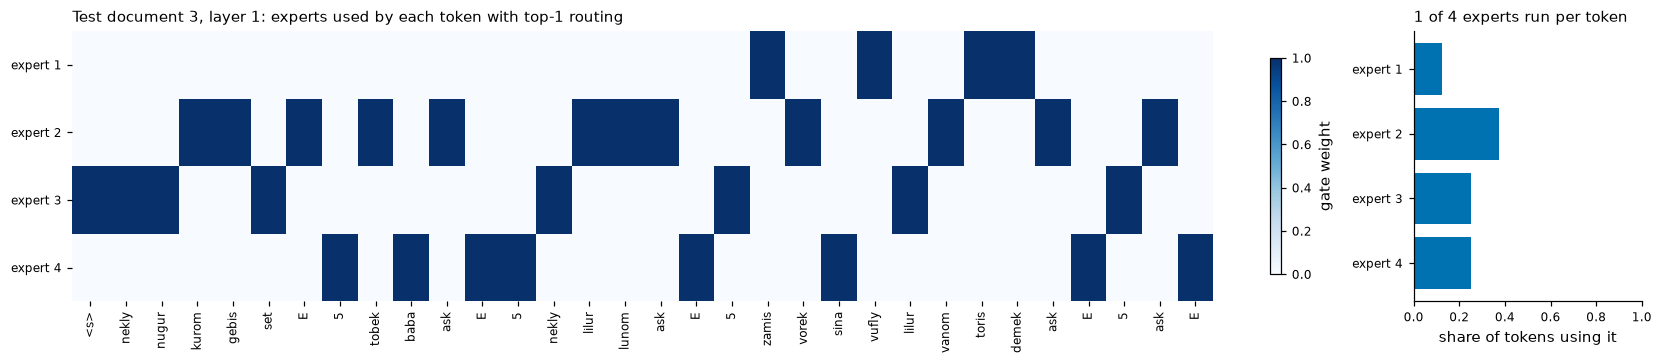

In [16]:
moe_model = models["MoE, balanced"]
def moe_explorer(top_k=1, document=3, layer=1):
    doc = test["tokens"][document][:32]
    with torch.no_grad():
        moe_model.hidden(torch.as_tensor(doc)[None])
    logits = moe_model.blocks[layer - 1].ffn.last_logits[0]                       # (tokens, experts)
    top = logits.topk(top_k, -1)
    gate = torch.zeros_like(logits).scatter(-1, top.indices, torch.softmax(top.values, -1)).numpy()
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.2), gridspec_kw=dict(width_ratios=[5, 1]))
    viz.heat(axes[0], gate.T, xlabels=[W.WORDS[t] for t in doc], ylabels=[f"expert {e + 1}" for e in range(gate.shape[1])], cmap="Blues", vmin=0, vmax=1, cbar="gate weight")
    axes[0].set_title(f"Test document {document}, layer {layer}: experts used by each token with top-{top_k} routing")
    axes[1].barh(range(gate.shape[1]), (gate > 0).mean(0), color=viz.BLUE); axes[1].set_yticks(range(gate.shape[1])); axes[1].set_yticklabels([f"expert {e + 1}" for e in range(gate.shape[1])])
    axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].set_xlabel("share of tokens using it"); axes[1].set_title(f"{top_k} of 4 experts run per token")
    plt.show()
viz.explore(moe_explorer, top_k=(1, 4, 1, 1), document=(0, 50, 1, 3), layer=(1, 2, 1, 1))

# Part C · What none of the five changes fixed

## 8. Looking up a value by its key: two layers, and time

Look back at the tables. Every transformer in Part B that learned recall at all reached the same numbers when two or
three bindings were alive: about 0.56 and 0.41. Those are the scores of a model that knows **which values have been
bound** and picks one of them without regard to the key (with two bindings the two values coincide one time in eight,
so guessing between them gives $\tfrac18 + \tfrac78 \cdot \tfrac12 = 0.56$). The attention LSTM of notebook 02 had no
such problem.

The reason is where the information sits. In `set D 8 ... ask D`, the query token `D` must find the `8`. But the `8`
is a different token from the `D` it was bound to, and nothing in the vector for `8` says which key it belongs to. In
the LSTM the state at `8` still remembered the `D` just before it, so one attention step was enough. A transformer
needs more than one attention step, because the key and the value sit at different positions.

### A route from the literature, and the prediction it makes

Studies of real language models found a two-step circuit for this kind of lookup, called an induction circuit
([Olsson et al., 2022](https://arxiv.org/abs/2209.11895)):

1. in the first layer, each bound value reads the token just before it and stores "I belong to key D";
2. in the second layer, the query `D` looks for the value that carries the tag `D`.

Neither step is useful without the other, so nothing pushes the model towards either until both begin to exist. That
is the proposed reason such circuits appear abruptly, after a long stretch in which nothing seems to happen
([Reddy, 2023](https://arxiv.org/abs/2312.03002)).

This route makes a prediction we can test: if our model uses it, then **after the first layer the key should be
readable from the model's internal vector at the bound value**.

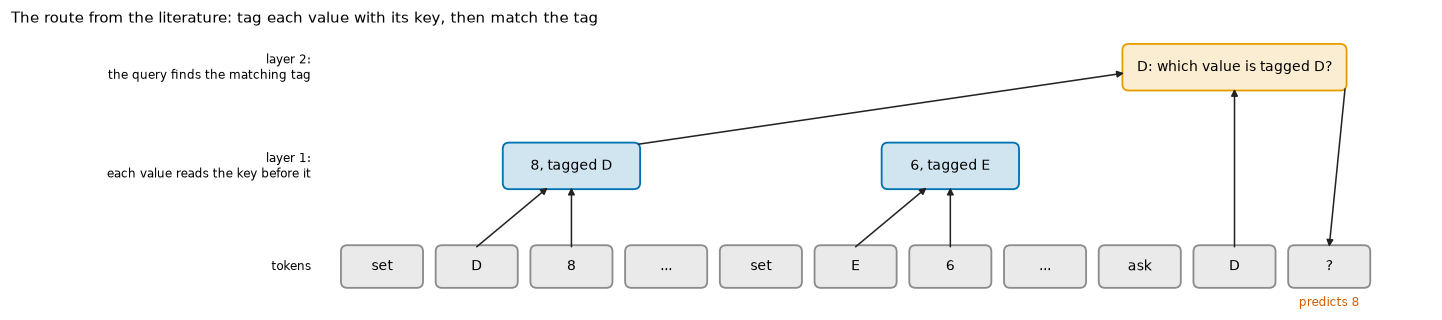

In [17]:
fig, ax = plt.subplots(figsize=(13, 3.6))
toks = ["set", "D", "8", "...", "set", "E", "6", "...", "ask", "D", "?"]
sx = 1.2
boxes = [(i * sx, 0, 1.0, 0.5, t, viz.GREY) for i, t in enumerate(toks)]
boxes += [(2 * sx - 0.35, 1.25, 1.7, 0.55, "8, tagged D", viz.BLUE), (6 * sx - 0.35, 1.25, 1.7, 0.55, "6, tagged E", viz.BLUE)]
boxes += [(9 * sx - 0.9, 2.5, 2.8, 0.55, "D: which value is tagged D?", viz.ORANGE)]
arrows = [(1 * sx + 0.5, 0.5, 2 * sx + 0.2, 1.25), (2 * sx + 0.5, 0.5, 2 * sx + 0.5, 1.25), (5 * sx + 0.5, 0.5, 6 * sx + 0.2, 1.25), (6 * sx + 0.5, 0.5, 6 * sx + 0.5, 1.25),
          (9 * sx + 0.5, 0.5, 9 * sx + 0.5, 2.5), (2 * sx + 1.35, 1.8, 9 * sx - 0.9, 2.7), (9 * sx + 1.9, 2.5, 10 * sx + 0.5, 0.5)]
viz.diagram(ax, boxes, arrows, fontsize=9)
for y, lab in [(0.25, "tokens"), (1.52, "layer 1:\neach value reads the key before it"), (2.77, "layer 2:\nthe query finds the matching tag")]:
    ax.text(-0.4, y, lab, ha="right", va="center", fontsize=8)
ax.text(10 * sx + 0.5, -0.25, "predicts 8", ha="center", fontsize=8, color=viz.VERMILION)
ax.set_xlim(-4.2, 11 * sx + 0.6); ax.set_title("The route from the literature: tag each value with its key, then match the tag")
plt.show()

### The long run

The next cell trains the modern block of Part B (pre-norm, RMSNorm, RoPE, SwiGLU) until recall with two and three
bindings is solved, or for 18,000 steps, whichever comes first. Every 500 steps it records recall and saves a copy of
the weights, so that we can go back and examine the model at any point.

In [18]:
snaps, done = [], [0]
def watch(step, model):
    if (step + 1) % 500 == 0:
        b = W.recall_by_bindings(model.logprobs)
        snaps.append(dict(step=step + 1, recall=b.values, state=copy.deepcopy(model.state_dict())))
        model.train()
        done[0] = done[0] + 1 if (b[2] > 0.99 and b[3] > 0.9) else 0
        return done[0] >= 2                            # stop once lookup has been solved at two checks in a row
fit("modern block, long run", steps=18000, callback=watch, **swiglu)
long_steps = snaps[-1]["step"]
print(f"stopped after {long_steps} steps")

modern block, long run             gap to floor 0.046   recall with 1 / 2 / 3 bindings alive: 1.00 / 1.00 / 0.94   (476s)
stopped after 13500 steps


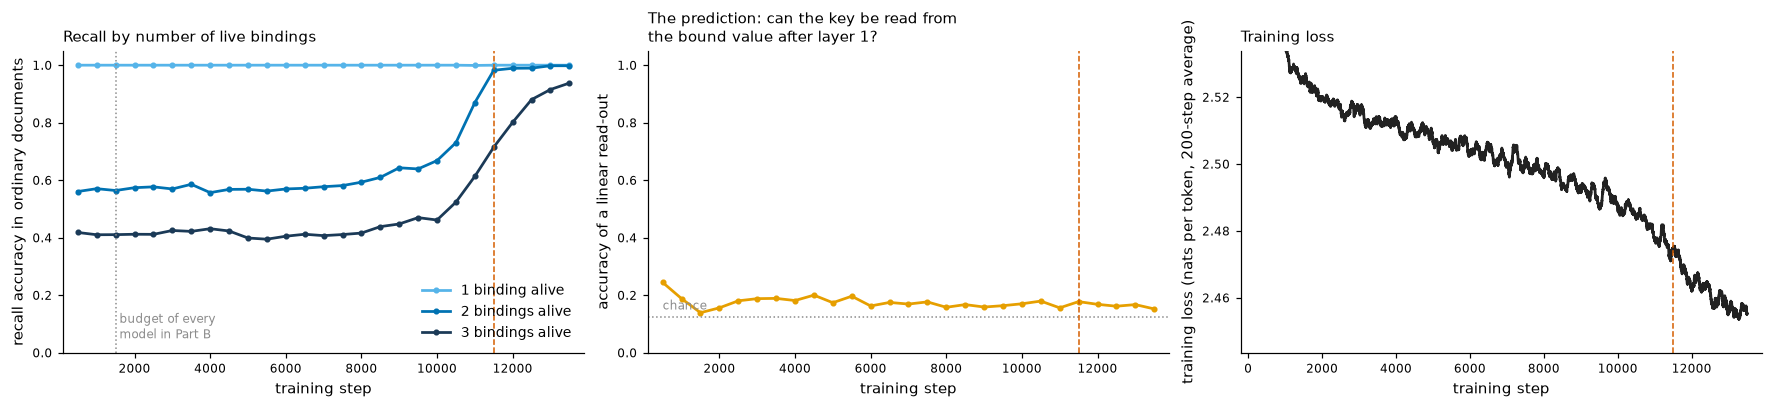

key read-out over the whole run: lowest 0.14, highest 0.24 (chance 0.125)


,1 binding,2 bindings,3 bindings,key readable at the bound value
step,,,,
1000,1.000,0.570,0.410,0.188
2000,1.000,0.574,0.412,0.156
3000,1.000,0.569,0.425,0.188
4000,1.000,0.557,0.431,0.181
5000,1.000,0.568,0.399,0.174
6000,1.000,0.569,0.405,0.163
7000,1.000,0.577,0.407,0.169
8000,1.000,0.593,0.416,0.158
9000,1.000,0.643,0.448,0.159


,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,"gap, positions 64-127",recall at distance 100,parameters,seconds
LSTM + dot-product attention,0.049,0.036,1.000,0.999,0.999,0.053,1.000,57105,37
2017 block,0.159,0.044,0.132,0.142,0.138,1.106,0.133,109905,40
"modern block, 1,500 steps",0.059,0.032,1.000,0.564,0.411,0.157,1.000,108817,50
"modern block, 13,500 steps",0.046,0.044,1.000,0.998,0.938,0.140,0.840,108817,476


In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
def readout(X, y):
    # accuracy of a linear classifier fitted on half of the examples and tested on the other half
    X, y = np.asarray(X), np.asarray(y); h = len(X) // 2
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X[:h], y[:h]).score(X[h:], y[h:])

scratch = T.Transformer(**swiglu)                      # a spare model to load saved weights into
def at(snap):
    scratch.load_state_dict(snap["state"]); scratch.eval()
    return scratch
pk, pt = test["kind"][:800], test["tokens"][:800]
bi, bp = np.where(pk == W.K_BVAL)
def tag_readable(model):
    # the test of the prediction: read the key from the vector at each bound value, after the first layer
    return readout(model.residuals(pt)[1][bi, bp], pt[bi, bp - 1])

steps = np.array([s["step"] for s in snaps]); rec = np.array([s["recall"] for s in snaps])
tag = np.array([tag_readable(at(s)) for s in snaps])
early = min(snaps, key=lambda s: abs(s["step"] - 1500))                 # the checkpoint at the budget used in Part B
jump = int(steps[np.argmax(rec[:, 1] > 0.9)]) if (rec[:, 1] > 0.9).any() else None
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for k, col in zip(range(3), [viz.SKY, viz.BLUE, "#1B3A57"]):
    axes[0].plot(steps, rec[:, k], "o-", ms=3, color=col, label=f"{k + 1} binding{'s' if k else ''} alive")
axes[0].axvline(1500, color=viz.GREY, ls=":", lw=1); axes[0].text(1600, 0.05, "budget of every\nmodel in Part B", fontsize=8, color=viz.GREY)
axes[0].set_ylim(0, 1.05); axes[0].set_xlabel("training step"); axes[0].set_ylabel("recall accuracy in ordinary documents"); axes[0].set_title("Recall by number of live bindings")
axes[0].legend(loc="lower right")
axes[1].plot(steps, tag, "o-", ms=3, color=viz.ORANGE); axes[1].axhline(1 / 8, color=viz.GREY, ls=":", lw=1); axes[1].text(steps[0], 0.15, "chance", fontsize=8, color=viz.GREY)
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("training step"); axes[1].set_ylabel("accuracy of a linear read-out")
axes[1].set_title("The prediction: can the key be read from\nthe bound value after layer 1?")
ls = np.array(res["modern block, long run"]["losses"]); k = 200
avg = np.convolve(ls, np.ones(k) / k, mode="valid")
axes[2].plot(np.arange(k - 1, len(ls)), avg, color=viz.BLACK)
axes[2].set_ylim(avg.min() - 0.01, avg[min(1500, len(avg) - 1)] + 0.01)
axes[2].set_xlabel("training step"); axes[2].set_ylabel("training loss (nats per token, 200-step average)"); axes[2].set_title("Training loss")
if jump:
    for ax in axes:
        ax.axvline(jump, color=viz.VERMILION, ls="--", lw=1)
plt.show()
print(f"key read-out over the whole run: lowest {tag.min():.2f}, highest {tag.max():.2f} (chance 0.125)")
display(pd.DataFrame({"1 binding": rec[:, 0], "2 bindings": rec[:, 1], "3 bindings": rec[:, 2], "key readable at the bound value": tag},
                     index=pd.Index(steps, name="step")).iloc[1::2].round(3))
FINAL = ["LSTM + dot-product attention", "2017 block", "RoPE + SwiGLU", "modern block, long run"]
display(table(FINAL, extra=(LONG, FAR), labels={"RoPE + SwiGLU": "modern block, 1,500 steps", "modern block, long run": f"modern block, {long_steps:,} steps"}).round(3))

**Reading the result.**

* *Nothing happens for a long time, then it happens quickly.* For the first 8,000 steps, recall with two and three
  bindings stays at 0.56 to 0.59 and about 0.41. It creeps up between steps 8,500 and 10,500 (0.67 with two bindings
  at step 10,000), then jumps: 0.87 at step 11,000 and 0.99 at step 12,000. Three bindings follow, reaching 0.94 when
  the run stops at 13,500 steps. The training loss shows the same event as a change of slope. The budget of 1,500
  steps used everywhere else in this series is a ninth of what this behaviour needed.
* *The final model is the best language model so far, narrowly.* Its gap to the floor is 0.046, against 0.049 for the
  attention LSTM and 0.059 for the same transformer at 1,500 steps. It took nine times the training, and the LSTM
  still recalls slightly better with three bindings (1.00 against 0.94).
* *One thing got worse.* Recall 100 tokens back, outside the training length, fell from 1.00 at 1,500 steps to 0.84.
  Behaviour outside the training range is not something training controls.
* *The prediction failed.* The key can be read from the bound value with an accuracy between 0.14 and 0.24
  throughout, close to the chance level of 0.125, and nothing changes at the jump. Whatever this model learned, it is
  not the tag-and-match circuit. (Challenge Problem 1 checks this with a second measurement.)

### So what did form? Removing one head at a time

A direct way to find out which parts of a network a behaviour depends on is to remove them one at a time and measure
the behaviour again. The model has eight attention heads. The cell below silences each in turn (its output is set to
zero; `prelib/transformer.py` has a switch for this) and measures recall, once for the checkpoint at 1,500 steps and
once for the final model.

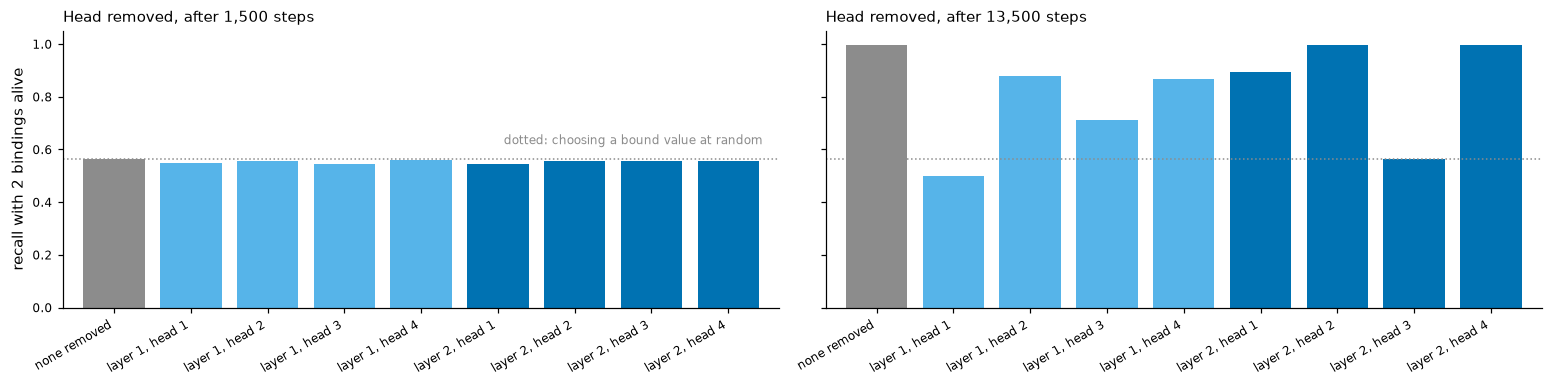

after 1,500 steps                       after 13,500 steps                      
                        1 binding 2 bindings 3 bindings          1 binding 2 bindings 3 bindings
none removed                 1.00       0.56       0.41               1.00       1.00       0.94
layer 1, head 1              0.82       0.55       0.39               0.74       0.50       0.36
layer 1, head 2              0.99       0.56       0.40               0.98       0.88       0.76
layer 1, head 3              0.88       0.55       0.40               0.80       0.71       0.57
layer 1, head 4              0.87       0.56       0.40               1.00       0.87       0.71
layer 2, head 1              1.00       0.54       0.41               0.99       0.89       0.73
layer 2, head 2              1.00       0.56       0.40               1.00       1.00       0.93
layer 2, head 3              1.00       0.56       0.41               1.00       0.56       0.44
layer 2, head 4              1.00       0.55       0.41               1.00       1.00       0.94

second-layer head that the lookup depends on most: layer 2, head 3


In [20]:
HEADS = [f"layer {l + 1}, head {h + 1}" for l in range(2) for h in range(4)]
def recall_without_each_head(snap):
    m = at(snap); rows = {"none removed": W.recall_by_bindings(m.logprobs).values}
    for l in range(2):
        for h in range(4):
            m.blocks[l].attn.ablate = h
            rows[HEADS[4 * l + h]] = W.recall_by_bindings(m.logprobs).values
            m.blocks[l].attn.ablate = None
    return pd.DataFrame(rows, index=["1 binding", "2 bindings", "3 bindings"]).T
WHEN = ["after 1,500 steps", f"after {long_steps:,} steps"]
removed = {WHEN[0]: recall_without_each_head(early), WHEN[1]: recall_without_each_head(snaps[-1])}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
for ax, w in zip(axes, WHEN):
    ax.bar(range(9), removed[w]["2 bindings"], color=[viz.GREY] + [viz.SKY] * 4 + [viz.BLUE] * 4)
    ax.axhline(0.5625, color=viz.GREY, ls=":", lw=1)
    ax.set_xticks(range(9)); ax.set_xticklabels(removed[w].index, rotation=30, ha="right"); ax.set_ylim(0, 1.05); ax.set_title(f"Head removed, {w}")
axes[0].set_ylabel("recall with 2 bindings alive"); axes[0].text(8.45, 0.62, "dotted: choosing a bound value at random", fontsize=8, color=viz.GREY, ha="right")
plt.show()
display(pd.concat(removed, axis=1).round(2))
crit = removed[WHEN[1]]["2 bindings"].iloc[5:].idxmin()                 # the second-layer head whose removal hurts most
crit_head = HEADS.index(crit) - 4
print("second-layer head that the lookup depends on most:", crit)

**Reading the result.** At 1,500 steps, removing any single head leaves recall with two bindings where it was, at
0.54 to 0.56. No head is doing key lookup, because nothing is. (Removing a first-layer head does hurt single-binding
recall, as the table shows: those heads fetch the bound values.)

In the final model one head stands out. Without **layer 2, head 3**, recall with two bindings falls from 1.00 to 0.56
and with three from 0.94 to 0.44, which is exactly the level of the plateau, while single-binding recall stays at
1.00. That one head carries the lookup. Removing head 1 of the same layer costs a little (0.89); removing heads 2 or
4 costs nothing. The first-layer heads matter as they did before the jump: they supply the raw material.

### What that head reads

The next cell collects every query in the first 400 test documents that arrives with two or three bindings alive,
and adds up where that one head reads from at the moment of the query. It also asks two read-out questions of the
model's internal vectors, before and after the jump.

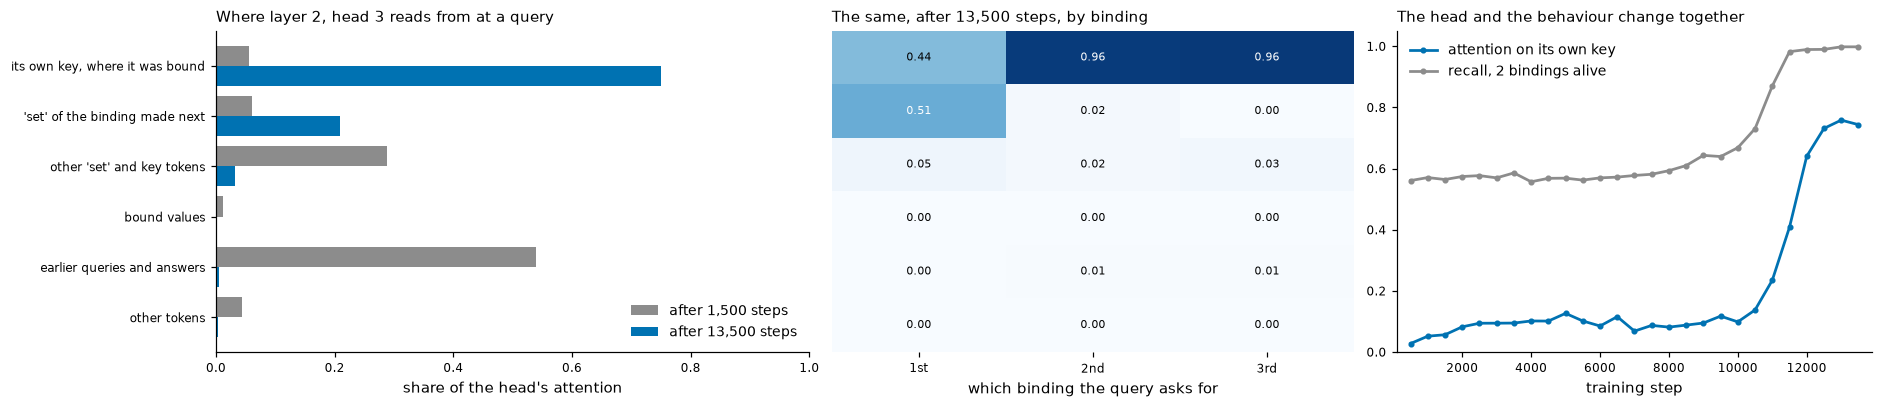

,"after 1,500 steps","after 13,500 steps"
"its own key, where it was bound",0.06,0.75
'set' of the binding made next,0.06,0.21
other 'set' and key tokens,0.29,0.03
bound values,0.01,0.00
earlier queries and answers,0.54,0.00
other tokens,0.04,0.00


,asks for the 1st binding,asks for the 2nd binding,asks for the 3rd binding
"its own key, where it was bound",0.44,0.96,0.96
'set' of the binding made next,0.51,0.02,0.00
other 'set' and key tokens,0.05,0.02,0.03
bound values,0.00,0.00,0.00
earlier queries and answers,0.00,0.01,0.01
other tokens,0.00,0.00,0.00


,"after 1,500 steps","after 13,500 steps"
"the previously bound value, read at the next key being bound (after layer 1)",0.791,0.766
"the correct answer, read at the query (after layer 1)",0.475,0.460
"the correct answer, read at the query (after layer 2)",0.458,0.959


In [21]:
CATS = ["its own key, where it was bound", "'set' of the binding made next", "other 'set' and key tokens", "bound values",
        "earlier queries and answers", "other tokens"]
ORDER = ["asks for the 1st binding", "asks for the 2nd binding", "asks for the 3rd binding"]
def reading_of(snap, head, n_docs=400):
    # share of the head's attention on each kind of earlier token, overall and by which binding the query asks for
    m = at(snap); total = dict.fromkeys(CATS, 0.0); by = np.zeros((len(CATS), 3)); n, n_by = 0, np.zeros(3)
    for i in range(n_docs):
        k, tk = test["kind"][i], test["tokens"][i]
        bound = np.where(k == W.K_BKEY)[0]
        queries = [t for t in np.where(k == W.K_QKEY)[0] if (bound < t).sum() >= 2]
        if not queries:
            continue
        A = m.attention_maps(tk)[1, head]
        for t in queries:
            before = bound[bound < t]
            order = [tk[p] for p in before].index(tk[t])                  # 0 = the query asks for the binding made first
            lab = np.full(t + 1, CATS[5], dtype=object)
            lab[k[:t + 1] == W.K_BVAL] = CATS[3]
            lab[np.isin(k[:t + 1], [W.K_ASK, W.K_QKEY, W.K_QVAL])] = CATS[4]
            lab[np.isin(k[:t + 1], [W.K_SET, W.K_BKEY])] = CATS[2]
            lab[before[order]] = CATS[0]
            if order + 1 < len(before):
                lab[before[order + 1] - 1] = CATS[1]
            share = np.array([A[t, :t + 1][lab == c].sum() for c in CATS])
            for c, s in zip(CATS, share):
                total[c] += s
            by[:, order] += share; n += 1; n_by[order] += 1
    return pd.Series(total) / n, pd.DataFrame(by / n_by, index=CATS, columns=ORDER)

def readouts(snap):
    m = at(snap); r = m.residuals(test["tokens"][:1500]); Xk, yk, X1, X2, yq = [], [], [], [], []
    for i in range(1500):
        k, tk = test["kind"][i], test["tokens"][i]; b = np.where(k == W.K_BVAL)[0]
        for j in range(1, len(b)):
            Xk.append(r[1][i, b[j] - 1]); yk.append(tk[b[j - 1]])          # at a key being bound: the value bound just before it
        for t in np.where(k == W.K_QKEY)[0]:
            if (b < t).sum() >= 2 and t + 1 < len(tk):
                X1.append(r[1][i, t]); X2.append(r[2][i, t]); yq.append(tk[t + 1])
    return {"the previously bound value, read at the next key being bound (after layer 1)": readout(Xk, yk),
            "the correct answer, read at the query (after layer 1)": readout(X1, yq),
            "the correct answer, read at the query (after layer 2)": readout(X2, yq)}

read_early, _ = reading_of(early, crit_head); read_final, by_order = reading_of(snaps[-1], crit_head)
own_key = np.array([reading_of(s, crit_head, n_docs=150)[0][CATS[0]] for s in snaps])
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1.25, 1.1, 1]))
y = np.arange(len(CATS))
axes[0].barh(y - 0.2, read_early[CATS], 0.4, color=viz.GREY, label=WHEN[0]); axes[0].barh(y + 0.2, read_final[CATS], 0.4, color=viz.BLUE, label=WHEN[1])
axes[0].set_yticks(y); axes[0].set_yticklabels(CATS); axes[0].invert_yaxis(); axes[0].set_xlim(0, 1); axes[0].set_xlabel("share of the head's attention")
axes[0].set_title(f"Where {crit} reads from at a query"); axes[0].legend(loc="lower right")
viz.heat(axes[1], by_order.values, xlabels=["1st", "2nd", "3rd"], ylabels=CATS, annotate=True, cmap="Blues", vmin=0, vmax=1)
axes[1].set_yticks([]); axes[1].set_xlabel("which binding the query asks for"); axes[1].set_title(f"The same, {WHEN[1]}, by binding")
axes[2].plot(steps, own_key, "o-", ms=3, color=viz.BLUE, label="attention on its own key")
axes[2].plot(steps, rec[:, 1], "o-", ms=3, color=viz.GREY, label="recall, 2 bindings alive")
axes[2].set_ylim(0, 1.05); axes[2].set_xlabel("training step"); axes[2].set_title("The head and the behaviour change together"); axes[2].legend(loc="upper left")
plt.show()
display(pd.DataFrame({WHEN[0]: read_early, WHEN[1]: read_final}).round(2))
display(by_order.round(2))
display(pd.DataFrame({WHEN[0]: readouts(early), WHEN[1]: readouts(snaps[-1])}).round(3))

**Reading the result.** Before the jump this head spread its attention over earlier queries and assorted `set` and
key tokens. After it, three quarters of its attention at a query goes to one place: **the earlier occurrence of the
queried key, where it was bound** (0.75 overall; 0.96 when the query asks for the second or third binding). That
share rises from about 0.1 to 0.75 over the same 2,000 steps in which recall jumps (right-hand panel). The head puts
no weight on the bound values themselves.

This is a different first move from the circuit in the literature, and an easier one: matching the `F` of a query
against the `F` in `set F 3` needs no preparation, because they are the same token. But the key's position cannot
contain its value. The value comes after it, and attention only looks backwards. What that position *can* contain is
whatever had already been bound when the key appeared, and the first read-out says it does: the value of the previous
binding can be read there with an accuracy of 0.77 to 0.79 (chance is 0.125), before the jump as much as after. The
first layer was collecting bound values at every position all along.

Together these suggest a lookup **by elimination**. The query already knows every value bound so far (from layer 1,
as before the jump). From its key's position it learns which values were bound *before* its key arrived. The answer
is among the rest. The pattern for the first binding fits this: nothing was bound before that key, and there the head
divides its attention between the key (0.44) and the `set` of the *next* binding (0.51), a position at which exactly
one value has been bound, the right one. The last two read-outs show where the decision is made. After layer 1 the
correct answer can be read from the query position with an accuracy of 0.46 to 0.48 at both checkpoints. After
layer 2 it is 0.46 before the jump and 0.96 after.

It is worth being exact about what was established. **Measured:** which head the behaviour depends on, where that
head reads, when that changed, and in which layer the answer becomes readable. **Not established:** the elimination
account as a whole. It is our reading of those measurements and was not tested by intervening on the vectors
themselves. The general lesson is safer than the particular mechanism: a network does not have to implement the
algorithm we would have written, and the way to find out what it does is to measure.

### Watching it form

The picture below takes one test document with three bindings and looks at a single moment: the model has just read
the queried key and must predict its value. Each row is one attention head; each column is an earlier position; the
shading is how much that head reads from that position. The three bound values are marked above the map, the correct
one in red. The key of each binding is the column just to the left of its marker.

document: <s> bizly gobur kolom set E 5 kugom gosis set F 3 tobek digek niza set G 6 pivly ask E 5 tovur libly lilur kolom zamis digek peza niza pivly lizur kolom neris tobek ask F 3 bala vufly nugur dafom zalis nugur potur musom zalis nugur kolom gosis dasek sina gobur neris ask E 5 demek ask F 3
the model has just read 'F' at position 59; the right answer is '3', bound at position 11 (its key is at position 10)


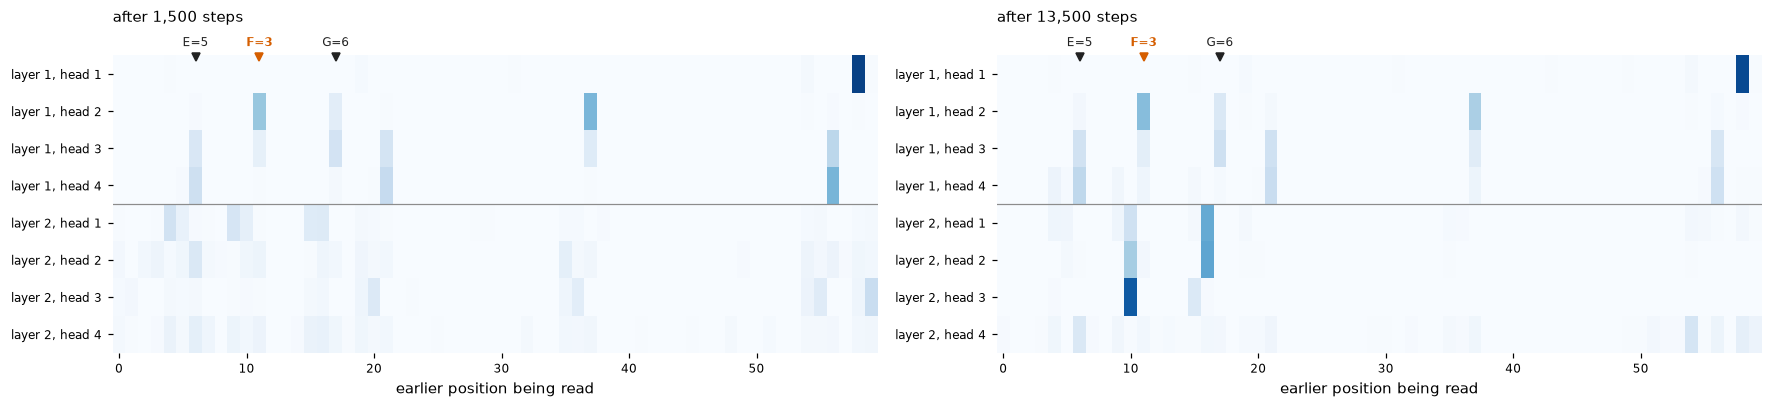

saved figures/nb03_circuit_forming.gif  (27 frames drawn, 429 kB)


'figures/nb03_circuit_forming.gif'

In [22]:
def pick_document():
    # a test document with three bindings to three different values, whose last query asks for the one made SECOND
    for i in range(len(test["tokens"])):
        k = test["kind"][i]; b = np.where(k == W.K_BVAL)[0]; q = np.where(k == W.K_QKEY)[0]
        if (len(b) == 3 and len(set(test["tokens"][i][b])) == 3 and len(q) and b[-1] + 1 < q[-1] < len(k) - 1
                and q[-1] + 1 - test["dist"][i][q[-1] + 1] == b[1]):
            return i, int(q[-1]), b
doc_id, qpos, bpos = pick_document()
right = 1                                              # index in bpos of the binding the query asks for
doc = test["tokens"][doc_id]; words = [W.WORDS[t] for t in doc]
print("document:", " ".join(words[:qpos + 2]))
print(f"the model has just read '{words[qpos]}' at position {qpos}; the right answer is '{words[qpos + 1]}', bound at position {bpos[right]} (its key is at position {bpos[right] - 1})")
def query_view(ax, snap):
    M = at(snap).attention_maps(doc)[:, :, qpos, :qpos + 1].reshape(8, -1)
    viz.heat(ax, M, ylabels=HEADS, cmap="Blues", vmin=0, vmax=1)
    ax.axhline(3.5, color=viz.GREY, lw=0.8)
    for j, p in enumerate(bpos):
        ax.text(p, -0.75, f"{words[p - 1]}={words[p]}", ha="center", fontsize=8, color=viz.VERMILION if j == right else viz.BLACK, fontweight="bold" if j == right else "normal")
        ax.plot([p], [-0.45], marker="v", color=viz.VERMILION if j == right else viz.BLACK, ms=5, clip_on=False)
    ax.set_xlabel("earlier position being read")
    return M
fig, axes = plt.subplots(1, 2, figsize=(16, 3.6))
query_view(axes[0], early); axes[0].set_title("after 1,500 steps", pad=22)
query_view(axes[1], snaps[-1]); axes[1].set_title(f"after {long_steps:,} steps", pad=22)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1, 2.2]))
def frame(f):
    axes[0].clear(); axes[1].clear()
    for k, col in zip(range(3), [viz.SKY, viz.BLUE, "#1B3A57"]):
        axes[0].plot(steps[:f + 1], rec[:f + 1, k], "o-", ms=3, color=col, label=f"{k + 1} binding{'s' if k else ''}")
    axes[0].set_xlim(0, steps[-1] + 500); axes[0].set_ylim(0, 1.05); axes[0].set_xlabel("training step"); axes[0].set_ylabel("recall accuracy"); axes[0].legend(loc="lower right", fontsize=8)
    axes[0].set_title(f"step {steps[f]:,}")
    query_view(axes[1], snaps[f]); axes[1].set_title("where each head reads from when answering the query", pad=22)
viz.save_gif(fig, frame, range(len(snaps)), "nb03_circuit_forming.gif", fps=3)

![Recall with two and three live bindings stays flat for thousands of steps, then rises quickly; at the same moment a second-layer head that had been reading diffusely starts to read one position sharply: the place where the queried key was bound](figures/nb03_circuit_forming.gif)

In this document the query asks for `F`, the second of three bindings (`E=5`, `F=3`, `G=6`). At 1,500 steps the
first-layer heads already read the bound values and their earlier repetitions, and the second-layer heads read
nothing in particular. In the final model, layer 2 head 3 reads position 10, the `F` of `set F 3`, and two other
second-layer heads read position 16, the key `G` of the binding made next. In the animation these dark cells appear
as the recall curve rises.

### All heads, whole document

The same model's eight heads over the whole document: row $t$, column $j$ is how much position $t$ reads from position
$j$. Diagonal stripes are heads that read a fixed distance back; isolated dark cells are lookups.

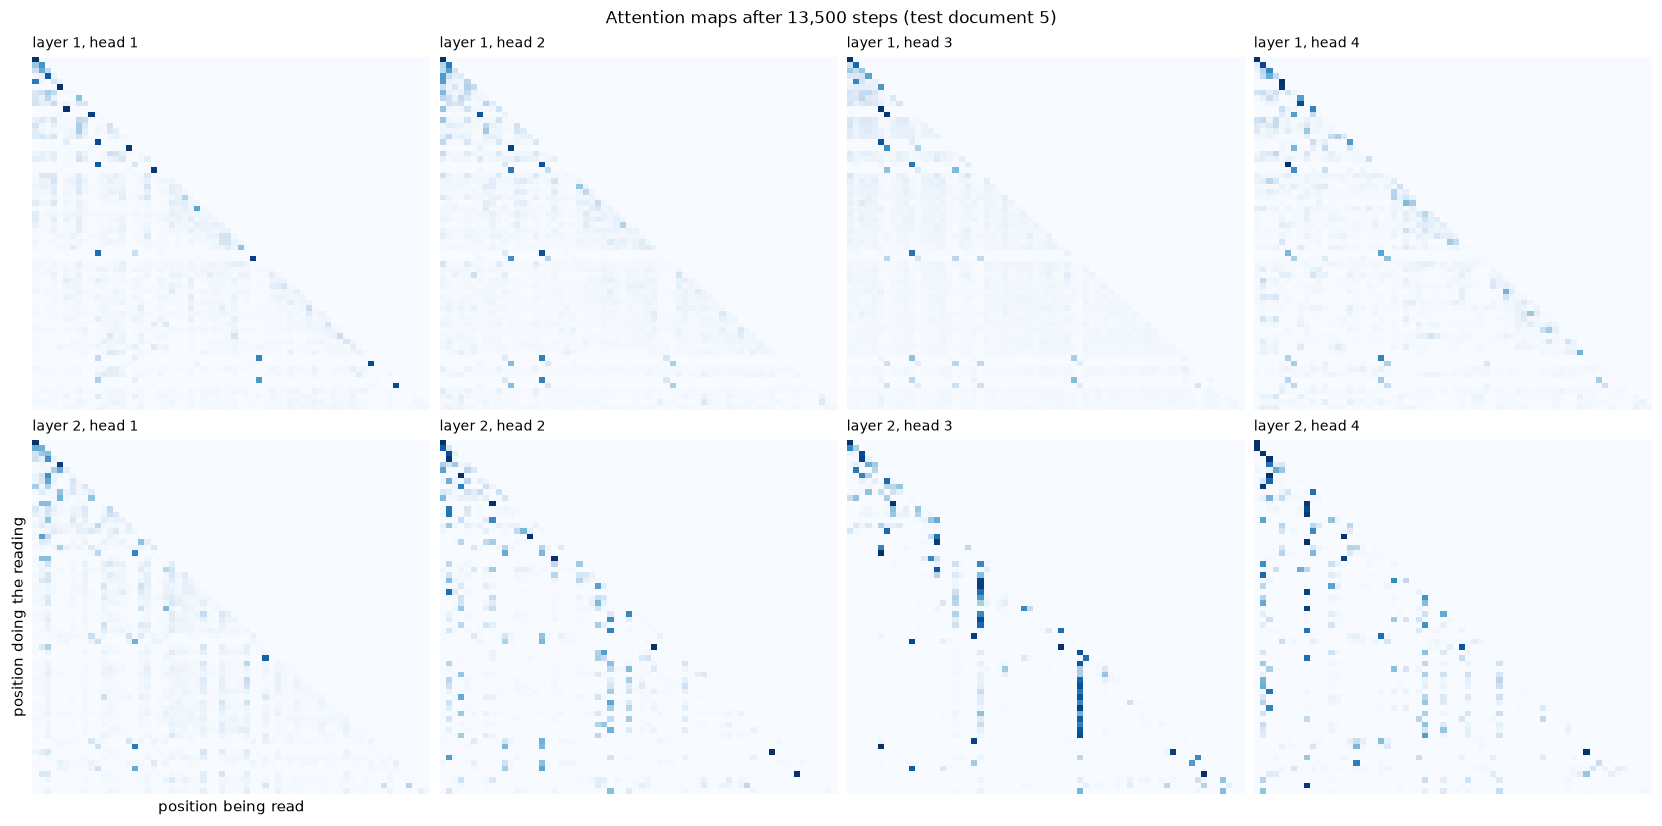

In [23]:
def all_heads(snap, title):
    A = at(snap).attention_maps(doc)
    fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
    for l in range(2):
        for h in range(4):
            viz.heat(axes[l, h], A[l, h], cmap="Blues", vmin=0, vmax=1)
            axes[l, h].set_title(f"layer {l + 1}, head {h + 1}", fontsize=9)
            axes[l, h].set_xticks([]); axes[l, h].set_yticks([])
    axes[1, 0].set_xlabel("position being read"); axes[1, 0].set_ylabel("position doing the reading")
    fig.suptitle(title); plt.show()
all_heads(snaps[-1], f"Attention maps after {long_steps:,} steps (test document {doc_id})")

### Try it: any head, before and after

Choose a checkpoint, a layer and a head. The left panel is that head's full attention map; the right panel shows the
document with each token shaded by how much the query position (outlined) reads from it.

Static preview at the default settings {'checkpoint': 'step 13,500', 'layer': 2, 'head': 3}. Run the notebook to get the controls.


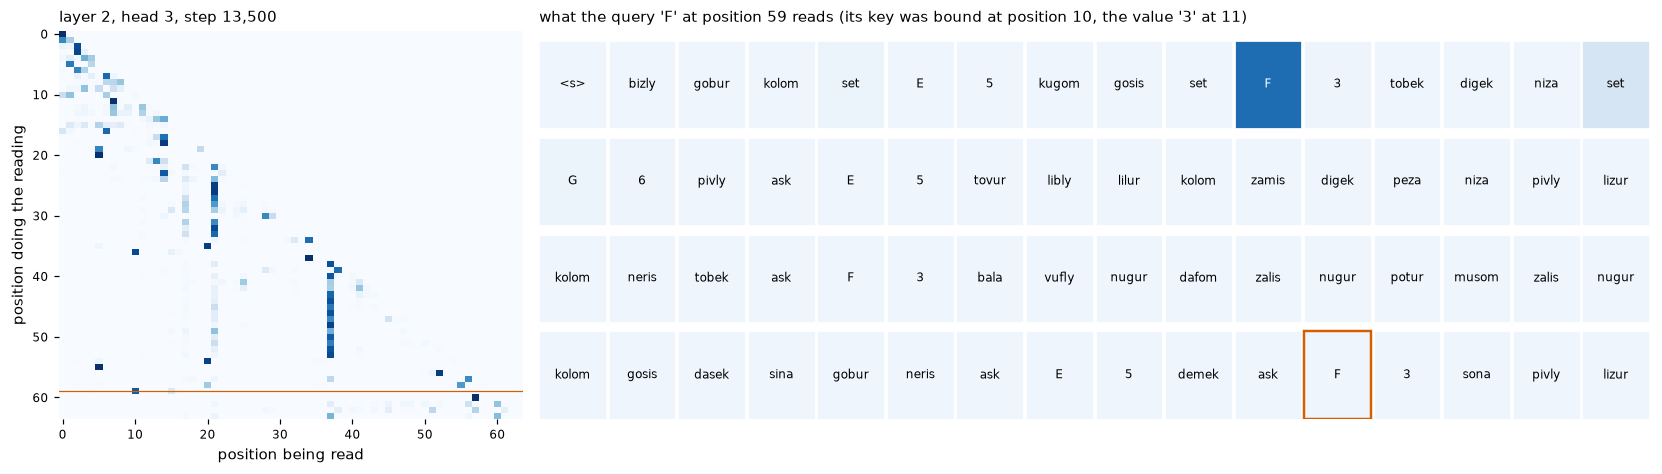

In [24]:
CHECKPOINTS = {f"step {s['step']:,}": s for s in snaps if s["step"] in (500, 1500, long_steps) or (jump and abs(s["step"] - jump) <= 1000)}
def attention_explorer(checkpoint=None, layer=2, head=1):
    snap = CHECKPOINTS[checkpoint or list(CHECKPOINTS)[-1]]
    A = at(snap).attention_maps(doc)[layer - 1, head - 1]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw=dict(width_ratios=[1, 2.4]))
    viz.heat(axes[0], A, cmap="Blues", vmin=0, vmax=1); axes[0].axhline(qpos, color=viz.VERMILION, lw=0.8)
    axes[0].set_xlabel("position being read"); axes[0].set_ylabel("position doing the reading"); axes[0].set_title(f"layer {layer}, head {head}, step {snap['step']:,}")
    vals = np.zeros(len(doc)); vals[:qpos + 1] = A[qpos, :qpos + 1]
    edge = [None] * len(doc); edge[qpos] = viz.VERMILION
    viz.token_strip(axes[1], words, values=vals, vmax=1.0, wrap=16, fontsize=8, edge=edge)
    axes[1].set_title(f"what the query '{words[qpos]}' at position {qpos} reads (its key was bound at position {bpos[right] - 1}, the value '{words[bpos[right]]}' at {bpos[right]})")
    plt.show()
viz.explore(attention_explorer, checkpoint=list(CHECKPOINTS)[::-1], layer=[2, 1], head=[crit_head + 1] + [h for h in range(1, 5) if h != crit_head + 1])

## 9. Design choices: what changed since 2017

The two blocks side by side. Everything in the right-hand column was introduced and measured above.

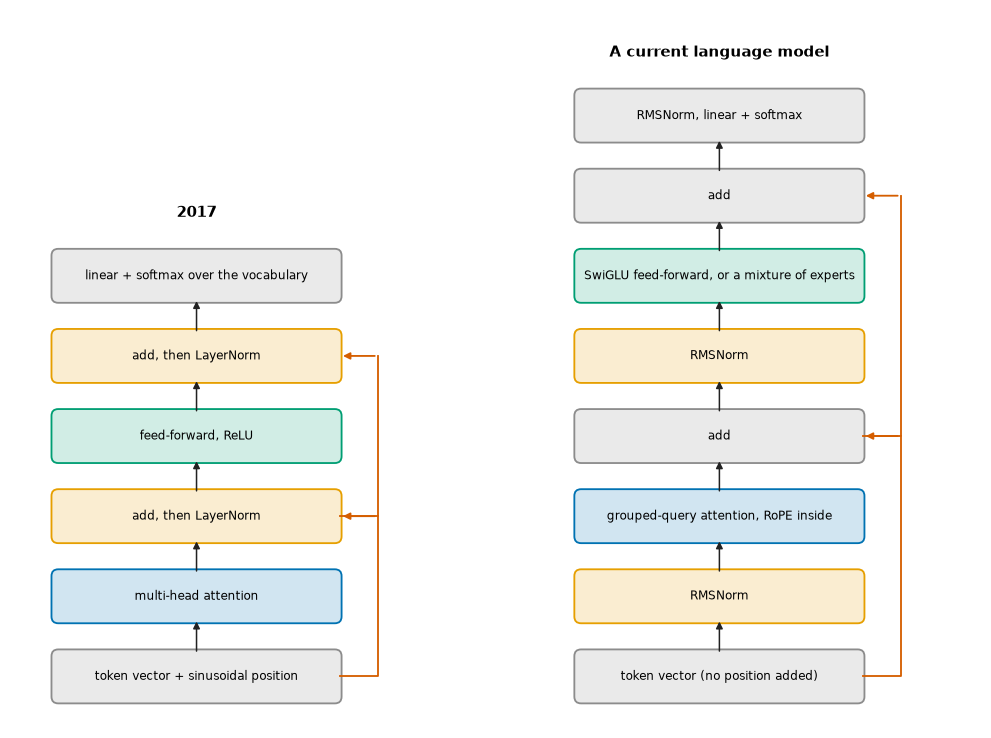

In [25]:
BLOCK_NOW = [("token vector (no position added)", viz.GREY, 0), ("RMSNorm", viz.ORANGE, 0), ("grouped-query attention, RoPE inside", viz.BLUE, 0), ("add", viz.GREY, 3),
             ("RMSNorm", viz.ORANGE, 0), ("SwiGLU feed-forward, or a mixture of experts", viz.GREEN, 0), ("add", viz.GREY, 3), ("RMSNorm, linear + softmax", viz.GREY, 0)]
fig, ax = plt.subplots(figsize=(11, 6.6))
block_diagram(ax, 0, BLOCK_2017, "2017")
block_diagram(ax, 6.2, BLOCK_NOW, "A current language model")
ax.set_xlim(-0.5, 11); ax.set_ylim(-0.3, 8.2)
plt.show()

| Choice | 2017 | What the field moved to | Why | Measured here |
|---|---|---|---|---|
| Normalisation placement | after the addition (post-norm) | before each sub-layer (pre-norm; [Xiong et al., 2020](https://arxiv.org/abs/2002.04745)) | Trains without warm-up and at larger depth | Six layers, large learning rate: post-norm without warm-up did not train, pre-norm did (section 3) |
| Normalisation | LayerNorm ([Ba et al., 2016](https://arxiv.org/abs/1607.06450)) | RMSNorm ([Zhang & Sennrich, 2019](https://arxiv.org/abs/1910.07467)) | Fewer operations, same quality | No difference we would attribute to it from one seed (section 3) |
| Position | sinusoidal vectors added at the input | learned vectors (BERT, GPT-2), then relative schemes: bias ([Shaw et al., 2018](https://arxiv.org/abs/1803.02155)), ALiBi ([Press et al., 2021](https://arxiv.org/abs/2108.12409)), RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) | Attention needs offsets, not addresses; relative schemes cope with longer inputs | Sinusoidal fails on longer documents (gap 0.85 against 0.11 to 0.13 for relative schemes); similar inside the training length (section 4) |
| Feed-forward activation | ReLU | GELU ([Hendrycks & Gimpel, 2016](https://arxiv.org/abs/1606.08415)), then SwiGLU ([Shazeer, 2020](https://arxiv.org/abs/2002.05202)) | Small, consistent gains in large models | No difference: gaps of 0.058, 0.058, 0.059 (section 5) |
| Attention heads | every head has its own keys and values | grouped-query attention ([Ainslie et al., 2023](https://arxiv.org/abs/2305.13245)) | Smaller key/value cache when generating | Cache 4 times smaller, gap unchanged within noise (section 6) |
| Feed-forward layer | one dense network | mixture of experts ([Shazeer et al., 2017](https://arxiv.org/abs/1701.06538), [Fedus et al., 2021](https://arxiv.org/abs/2101.03961), [Jiang et al., 2024](https://arxiv.org/abs/2401.04088)) | More parameters without more computation per token | No gain at this size; routing specialises by token type; the balancing loss evens the load (section 7) |
| Attention implementation | full score matrix in memory | memory-efficient kernels such as FlashAttention ([Dao et al., 2022](https://arxiv.org/abs/2205.14135)) | Same mathematics, less memory traffic | not ablated: no effect on results by design |
| Learning-rate schedule, weight tying, tokeniser | warm-up then decay; tied embeddings; BPE | covered in notebook 05 | | notebook 05 |

**Where each choice appears in well-known models** (from the cited papers):

| Model | Normalisation | Position | Feed-forward | Attention | Experts |
|---|---|---|---|---|---|
| Transformer ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) | post, LayerNorm | sinusoidal | ReLU | multi-head | dense |
| GPT-2 / GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | pre, LayerNorm | learned absolute | GELU | multi-head | dense |
| LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)) | pre, RMSNorm | RoPE | SwiGLU | multi-head | dense |
| Llama 3 ([Grattafiori et al., 2024](https://arxiv.org/abs/2407.21783)) | pre, RMSNorm | RoPE | SwiGLU | grouped-query | dense |
| Mixtral 8x7B ([Jiang et al., 2024](https://arxiv.org/abs/2401.04088)) | pre, RMSNorm | RoPE | SwiGLU | grouped-query | 8 experts, 2 per token |

## 10. Scorecard

In [26]:
rows = []
for name, label in [("2017 block", "transformer, 2017 block"), ("pre-norm + RMSNorm", "transformer, pre-norm + RMSNorm"), ("RoPE", "transformer, + RoPE"),
                    ("RoPE + SwiGLU", "transformer, modern block (RoPE, RMSNorm, SwiGLU)"), ("GQA, 1 key/value head", "transformer, modern + 1 key/value head"),
                    ("MoE, balanced", "transformer, modern + MoE (4 experts, top-1)"), ("modern block, long run", f"transformer, modern block, {long_steps:,} steps")]:
    rows.append(W.scorecard_row(label, res[name], recall_natural=W.natural_recall(models[name].logprobs).correct.mean(),
                                probe_style=W.probe(models[name].features, 100, "style"), params=res[name]["params"], train_seconds=res[name]["seconds"]))
metrics.append_rows(rows, "03_transformer")
card = metrics.load_scorecard()
display(card[card.notebook != "01_ngrams_embeddings"][["notebook", "model", "gap", "recall_d8", "recall_d32", "recall_natural", "probe_style", "params", "train_seconds"]].round(3))

,notebook,model,gap,recall_d8,recall_d32,recall_natural,probe_style,params,train_seconds
6,02_recurrent,plain RNN,0.326,0.132,0.114,0.137,0.997,18769.0,12.634
7,02_recurrent,GRU,0.243,0.154,0.128,0.153,1.000,35409.0,39.122
8,02_recurrent,"LSTM, 64 units",0.170,0.850,0.662,0.546,1.000,43729.0,43.919
9,02_recurrent,"LSTM, 128 units",0.080,1.000,1.000,0.651,1.000,152913.0,68.919
10,02_recurrent,LSTM + dot-product attention,0.049,1.000,1.000,0.999,1.000,57105.0,53.847
11,02_recurrent,LSTM + additive attention,0.113,0.978,0.850,0.630,1.000,57169.0,83.641
12,03_transformer,"transformer, 2017 block",0.159,0.154,0.122,0.137,0.992,109905.0,40.227
13,03_transformer,"transformer, pre-norm + RMSNorm",0.085,1.000,1.000,0.633,0.928,109713.0,44.623
14,03_transformer,"transformer, + RoPE",0.058,1.000,1.000,0.639,0.749,109713.0,47.953
15,03_transformer,"transformer, modern block (RoPE, RMSNorm, SwiGLU)",0.059,1.000,1.000,0.642,0.991,108817.0,49.842


## Challenge Problem 1: Check the failed prediction a second way

The read-out in section 8 said that this model does not tag bound values with their keys. Check that with a different measurement. Step 1 of the
route from the literature needs some head to read, from each bound value at position `p`, the key at position `p - 1`. For the checkpoint at 1,500
steps and for the last one, load the weights with `at(snap)` and measure, for each of the eight heads, the average attention weight from a
bound-value position `p` to position `p - 1` over the first 200 test documents. Does any head do this job, before or after the jump?

In [27]:
# Start your code here

### Challenge Problem 1 Solution

,"after 1,500 steps","after 13,500 steps"
"layer 1, head 1",0.01,0.01
"layer 1, head 2",0.01,0.03
"layer 1, head 3",0.02,0.03
"layer 1, head 4",0.02,0.05
"layer 2, head 1",0.02,0.01
"layer 2, head 2",0.00,0.00
"layer 2, head 3",0.00,0.00
"layer 2, head 4",0.00,0.00


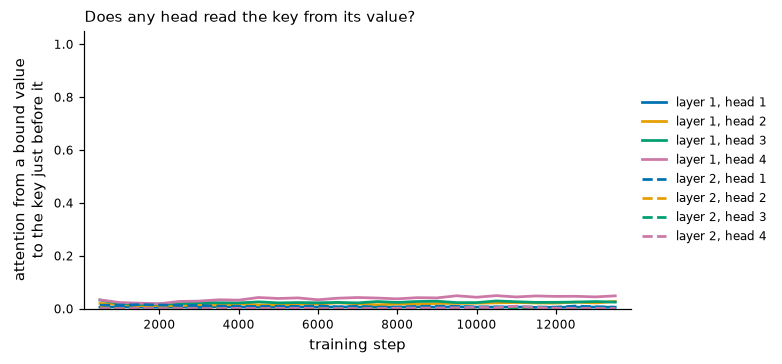

In [28]:
def reads_previous(snap, n_docs=200):
    m = at(snap); total = np.zeros((2, 4)); n = 0
    for i in range(n_docs):
        A = m.attention_maps(test["tokens"][i])
        for p in np.where(test["kind"][i] == W.K_BVAL)[0]:
            total += A[:, :, p, p - 1]; n += 1
    return (total / n).reshape(-1)
prev = pd.DataFrame({"after 1,500 steps": reads_previous(early), f"after {long_steps:,} steps": reads_previous(snaps[-1])}, index=HEADS)
display(prev.round(2))
track = np.array([reads_previous(s, 60) for s in snaps])
fig, ax = plt.subplots(figsize=(7, 3.2))
for j, name in enumerate(HEADS):
    ax.plot(steps, track[:, j], color=viz.CYCLE[j % 4], ls="-" if j < 4 else "--", label=name)
ax.set_xlabel("training step"); ax.set_ylabel("attention from a bound value\nto the key just before it"); ax.set_ylim(0, 1.05)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8); ax.set_title("Does any head read the key from its value?"); plt.show()
# Read the table: no head does this job. The average attention from a bound value to the key just before it is at
# most 0.05 for every head, at 1,500 steps and after the jump, and the curves stay flat through training. This agrees
# with the read-out in section 8: the model does not tag values with their keys. Two different measurements giving the
# same answer is what makes a negative result believable.

## Challenge Problem 2: Can one layer do it?

Train the modern block with a single layer (`n_layer=1`) for the standard 1,500 steps using `fit`, and compare its recall with one, two and three
live bindings with the two-layer model at 1,500 steps and after the long run. Then argue, from the two-step description in section 8, whether training
the one-layer model for longer could ever solve the two- and three-binding cases.

In [29]:
# Start your code here

### Challenge Problem 2 Solution

In [30]:
fit("modern block, one layer", n_layer=1, **swiglu)
display(table(["modern block, one layer", "RoPE + SwiGLU", "modern block, long run"],
              labels={"RoPE + SwiGLU": "two layers, 1,500 steps", "modern block, long run": f"two layers, {long_steps:,} steps"}).round(3))
# Read the table: one layer learns single-binding recall (1.00) and stops at 0.57 and 0.41 with two and three
# bindings, the same plateau as the two-layer model at 1,500 steps. Its gap to the floor is also much larger (0.156
# against 0.059), mostly on filler words: one layer is worse at word order too.
# Longer training cannot fix the lookup. With one layer, the query reads token vectors only (plus what RoPE says about
# distance). The vector of a value token does not depend on which key came before it, so nothing the query can read
# separates the right value from the others. Both routes described in section 8 need an earlier layer to write
# something about the context into some position first. Depth is what makes composition possible; section 8 showed
# that even with enough depth, finding the composition takes time.

modern block, one layer            gap to floor 0.156   recall with 1 / 2 / 3 bindings alive: 1.00 / 0.57 / 0.41   (33s)


,gap to floor,"gap, filler words","recall, 1 binding",2 bindings,3 bindings,parameters,seconds
"modern block, one layer",0.156,0.177,1.0,0.568,0.413,59665,33
"two layers, 1,500 steps",0.059,0.032,1.0,0.564,0.411,108817,50
"two layers, 13,500 steps",0.046,0.044,1.0,0.998,0.938,108817,476


## Final summary

* A transformer layer is attention plus a per-position feed-forward network, held together by residual connections
  and normalisation. All positions are computed at once, and position has to be supplied separately.
* At equal training steps and small scale, the 2017 block was **behind** the attention LSTM of notebook 02, and no
  faster on a CPU. Its advantages are parallel hardware and scale, and a laptop experiment shows neither.
* Of the five changes since 2017, two made a measurable difference here: **pre-norm** (trains where post-norm needs
  a warm-up) and **relative position schemes** (cope with documents longer than those seen in training, where
  sinusoidal positions failed). Three were neutral at this size and are about cost or scale: **SwiGLU**,
  **grouped-query attention** (a cache four times smaller at the same quality) and **mixture of experts** (three
  times the parameters at the same computation per token, with no gain on a task this small).
* The behaviour that separated the transformer from the LSTM, **choosing the right binding among several**, depended
  on none of those choices. It needed two layers and nine times the training, and it appeared abruptly after a long
  plateau.
* The model did not learn the circuit described in the literature. Removing heads and fitting read-outs showed a
  single second-layer head that finds where the queried key was bound. Measure what a network does before explaining
  it.
* What is still missing: the model has been trained with one objective, next-token prediction, and we have not asked
  what its representations are good for. Notebook 04 compares pretraining objectives and how each one transfers.

## References

* Ashish Vaswani, Noam Shazeer, Niki Parmar et al. (2017). **Attention Is All You Need**. arXiv:1706.03762. [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
* Kaiming He, Xiangyu Zhang, Shaoqing Ren et al. (2015). **Deep Residual Learning for Image Recognition**. arXiv:1512.03385. [arxiv.org/abs/1512.03385](https://arxiv.org/abs/1512.03385)
* Jimmy Lei Ba, Jamie Ryan Kiros, Geoffrey E. Hinton (2016). **Layer Normalization**. arXiv:1607.06450. [arxiv.org/abs/1607.06450](https://arxiv.org/abs/1607.06450)
* Ruibin Xiong, Yunchang Yang, Di He et al. (2020). **On Layer Normalization in the Transformer Architecture**. arXiv:2002.04745. [arxiv.org/abs/2002.04745](https://arxiv.org/abs/2002.04745)
* Biao Zhang, Rico Sennrich (2019). **Root Mean Square Layer Normalization**. arXiv:1910.07467. [arxiv.org/abs/1910.07467](https://arxiv.org/abs/1910.07467)
* Peter Shaw, Jakob Uszkoreit, Ashish Vaswani (2018). **Self-Attention with Relative Position Representations**. arXiv:1803.02155. [arxiv.org/abs/1803.02155](https://arxiv.org/abs/1803.02155)
* Ofir Press, Noah A. Smith, Mike Lewis (2021). **Train Short, Test Long: Attention with Linear Biases Enables Input Length Extrapolation**. arXiv:2108.12409. [arxiv.org/abs/2108.12409](https://arxiv.org/abs/2108.12409)
* Jianlin Su, Yu Lu, Shengfeng Pan et al. (2021). **RoFormer: Enhanced Transformer with Rotary Position Embedding**. arXiv:2104.09864. [arxiv.org/abs/2104.09864](https://arxiv.org/abs/2104.09864)
* Adi Haviv, Ori Ram, Ofir Press et al. (2022). **Transformer Language Models without Positional Encodings Still Learn Positional Information**. arXiv:2203.16634. [arxiv.org/abs/2203.16634](https://arxiv.org/abs/2203.16634)
* Dan Hendrycks, Kevin Gimpel (2016). **Gaussian Error Linear Units (GELUs)**. arXiv:1606.08415. [arxiv.org/abs/1606.08415](https://arxiv.org/abs/1606.08415)
* Noam Shazeer (2020). **GLU Variants Improve Transformer**. arXiv:2002.05202. [arxiv.org/abs/2002.05202](https://arxiv.org/abs/2002.05202)
* Joshua Ainslie, James Lee-Thorp, Michiel de Jong et al. (2023). **GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints**. arXiv:2305.13245. [arxiv.org/abs/2305.13245](https://arxiv.org/abs/2305.13245)
* Robert A. Jacobs, Michael I. Jordan, Steven J. Nowlan et al. (1991). **Adaptive Mixtures of Local Experts**. *Neural Computation*. [doi.org/10.1162/neco.1991.3.1.79](https://doi.org/10.1162/neco.1991.3.1.79)
* Noam Shazeer, Azalia Mirhoseini, Krzysztof Maziarz et al. (2017). **Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer**. arXiv:1701.06538. [arxiv.org/abs/1701.06538](https://arxiv.org/abs/1701.06538)
* William Fedus, Barret Zoph, Noam Shazeer (2021). **Switch Transformers: Scaling to Trillion Parameter Models with Simple and Efficient Sparsity**. arXiv:2101.03961. [arxiv.org/abs/2101.03961](https://arxiv.org/abs/2101.03961)
* Albert Q. Jiang, Alexandre Sablayrolles, Antoine Roux et al. (2024). **Mixtral of Experts**. arXiv:2401.04088. [arxiv.org/abs/2401.04088](https://arxiv.org/abs/2401.04088)
* Hugo Touvron, Thibaut Lavril, Gautier Izacard et al. (2023). **LLaMA: Open and Efficient Foundation Language Models**. arXiv:2302.13971. [arxiv.org/abs/2302.13971](https://arxiv.org/abs/2302.13971)
* Aaron Grattafiori, Abhimanyu Dubey, Abhinav Jauhri et al. (2024). **The Llama 3 Herd of Models**. arXiv:2407.21783. [arxiv.org/abs/2407.21783](https://arxiv.org/abs/2407.21783)
* Tom B. Brown, Benjamin Mann, Nick Ryder et al. (2020). **Language Models are Few-Shot Learners**. arXiv:2005.14165. [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
* Tri Dao, Daniel Y. Fu, Stefano Ermon et al. (2022). **FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness**. arXiv:2205.14135. [arxiv.org/abs/2205.14135](https://arxiv.org/abs/2205.14135)
* Catherine Olsson, Nelson Elhage, Neel Nanda et al. (2022). **In-context Learning and Induction Heads**. arXiv:2209.11895. [arxiv.org/abs/2209.11895](https://arxiv.org/abs/2209.11895)
* Gautam Reddy (2023). **The mechanistic basis of data dependence and abrupt learning in an in-context classification task**. arXiv:2312.03002. [arxiv.org/abs/2312.03002](https://arxiv.org/abs/2312.03002)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).